# Telco Customer Churn Prediction: Analysis and Data Preparation for an Early-Warning Model

This notebook analyses why customers of a fictional California telecom provider churn, and prepares a leakage-free dataset for a Gradient Boosting model that flags customers at risk of leaving. Roughly one in four customers (26.5%) left in a single quarter. The prepared data and preprocessing artifacts feed the modeling script (`pipelines/train.py`) and a Streamlit prototype for the retention team. The notebook follows the CRISP-DM framework:

| # | Section | CRISP-DM phase | Purpose |
|---|---|---|---|
| 1 | Project Overview | Business Understanding | Context, industry benchmarks and references |
| 2 | Business Understanding | Business Understanding | Problem statements, goals, situation assessment, success criteria and solution approach |
| 3 | Setup | — (technical setup) | Libraries, minimum versions and project-wide configuration |
| 4 | Data Understanding | Data Understanding | Acquire, describe, verify and explore the data |
| 5 | Data Preparation | Data Preparation | Select, clean, construct and format the data, and fix the test design |
| 6 | Modelling | Modeling | Prototype: baselines, Optuna tuning, model selection and decision thresholds |
| 7 | Evaluation | Evaluation | Held-out test assessment, benchmarks, success criteria, process review and next steps |
| 8 | Deployment | Deployment | Exported artifacts, hand-off to the tracked MLflow run, serving and monitoring |
| 9 | Conclusion and Recommendations | Evaluation (summary) | Outcomes against the goals, prescriptive actions and limitations |

CRISP-DM is iterative, and this notebook deviates from the textbook task order in two deliberate places. Both are marked where they occur:

* **Modelling is prototyped here, then repeated as a tracked run.** Sections 6–7 train and evaluate the model in memory. The final, reproducible training run with MLflow experiment tracking happens in `pipelines/train.py` (Section 8.2), and serving runs in separate scripts.
* **The test design (5.2) is fixed during Data Preparation.** This is a Modeling task, but fixing the split early lets every fitted preparation step use the training split only.

**Key findings at a glance**
* Contract type is the strongest churn signal: month-to-month customers churn at 45.8%, versus 2.6% for two-year contracts.
* Churn concentrates in the first months of tenure, among fiber-optic internet users, and among customers without protective add-ons such as online security and premium tech support.
* Several columns describe the churn event itself (churn reason, churn score, customer status) and are excluded to prevent *data leakage*, i.e. giving the model information it would not have at prediction time.

## 1. Project Overview

**A customer who has already decided to leave is expensive to win back. Retention works best when the risk is visible before the cancellation request.**

*Customer churn* is the loss of customers who stop using a company's services. For a subscription business such as telecommunications, every churned customer means lost recurring revenue plus the cost of acquiring a replacement. Estimates of how much more expensive acquisition is than retention range from 5 to 25 times, depending on the study and industry (Gallo, 2014).

**How high is churn in this case study?** In Q3 2025, the three largest U.S. carriers reported postpaid phone churn between 0.89% and 0.92% (AT&T, 2025; T-Mobile, 2025; Verizon, 2025), and Verizon reported 0.94% for Q3 2026 (Verizon, 2026). Carriers conventionally report this as an average *monthly* rate, which corresponds to roughly 2.6–2.7% of customers per quarter. The fictional company in this dataset lost **26.5% of its customers in a single quarter**, about ten times that level. The figures are not directly comparable: the data is synthetic (IBM, 2019) and describes home phone and internet customers, half of whom (51.3%) are on month-to-month contracts. The dataset is therefore best read as a **high-churn stress scenario**, where an early-warning model has the most room to add value.

**What drives churn?** A systematic review of 37 telecom studies identifies age, gender, satisfaction, switching costs and barriers, and service quality as the most frequently reported determinants (Ribeiro et al., 2024). J.D. Power's 2025 U.S. Wireless Carrier Satisfaction Study (56,450 customers) finds that "value is the most important driver of the overall experience, followed closely by service quality" (J.D. Power, 2025b). The dataset tells a consistent story: among the 1,869 churned customers, **"Competitor" is the most common churn category (841 customers, 45.0%)**, and the single most frequent reason is "Competitor had better devices" (313 customers, 16.7%). These reason columns are used only to understand the problem; they are excluded from the model because they are recorded after the customer leaves (Section 5.1).

**Why prediction alone is not enough.** The customers most likely to churn are not always the ones a retention offer can save. Field experiments show that targeting purely on churn risk can make retention spending ineffective, and that campaigns should target customers whose behavior the offer actually changes (Ascarza, 2018; Lemmens & Gupta, 2020). Model evaluation should therefore be tied to the profit of the retention campaign, not only to statistical accuracy (Manzoor et al., 2024; Verbraken et al., 2013).

### 1.1 References

Citations follow APA 7th edition.

#### Company, industry and business reports

AT&T. (2025, October 22). *AT&T reports strong third-quarter financial performance* [Press release]. https://about.att.com/story/2025/3q-earnings.html

Gallo, A. (2014, October 29). The value of keeping the right customers. *Harvard Business Review*. https://hbr.org/2014/10/the-value-of-keeping-the-right-customers

IBM. (2019, July 11). *Telco customer churn (11.1.3+)* [Sample data module, IBM Cognos Analytics]. IBM Community. https://community.ibm.com/community/user/businessanalytics/blogs/steven-macko/2019/07/11/telco-customer-churn-1113

J.D. Power. (2025a, January 30). *Wireless product complexities and evolving customer expectations lead to drop in customer care satisfaction, J.D. Power finds* [Press release]. Business Wire. https://www.businesswire.com/news/home/20250130315505/en/

J.D. Power. (2025b, July 31). *J.D. Power: New wireless carrier benchmark study highlights importance of strong value proposition* [Press release]. Business Wire. https://www.businesswire.com/news/home/20250731579376/en/

T-Mobile US. (2025, October 23). *T-Mobile delivers record customer growth, fueled by widening differentiation and focus on durable and profitable financial growth, raises guidance across the board* [Press release]. https://www.t-mobile.com/news/business/t-mobile-q3-2025-earnings

Verizon. (2025, October 29). *Verizon reports 3Q 2025 earnings; reiterates full-year financial guidance* [Press release]. https://www.verizon.com/about/news/verizon-reports-3q-2025-earnings-reiterates-full-year-financial-guidance

Verizon. (2026, October 26). *[Third-quarter 2026 earnings press release]*. https://www.verizon.com/about/news/verizon-delivers-another-record-breaking-quarter

#### Scientific papers

Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. In *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining* (pp. 2623–2631). ACM. https://doi.org/10.1145/3292500.3330701

Ascarza, E. (2018). Retention futility: Targeting high-risk customers might be ineffective. *Journal of Marketing Research, 55*(1), 80–98. https://doi.org/10.1509/jmr.16.0163

Dal Pozzolo, A., Caelen, O., Johnson, R. A., & Bontempi, G. (2015). Calibrating probability with undersampling for unbalanced classification. In *2015 IEEE Symposium Series on Computational Intelligence* (pp. 159–166). IEEE. https://doi.org/10.1109/SSCI.2015.33

de Haan, E., Verhoef, P. C., & Wiesel, T. (2015). The predictive ability of different customer feedback metrics for retention. *International Journal of Research in Marketing, 32*(2), 195–206. https://doi.org/10.1016/j.ijresmar.2015.02.004

Garnefeld, I., Eggert, A., Helm, S. V., & Tax, S. S. (2013). Growing existing customers' revenue streams through customer referral programs. *Journal of Marketing, 77*(4), 17–32. https://doi.org/10.1509/jm.11.0423

Gustafsson, A., Johnson, M. D., & Roos, I. (2005). The effects of customer satisfaction, relationship commitment dimensions, and triggers on customer retention. *Journal of Marketing, 69*(4), 210–218. https://doi.org/10.1509/jmkg.2005.69.4.210

Kaufman, S., Rosset, S., Perlich, C., & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data, 6*(4), 1–21. https://doi.org/10.1145/2382577.2382579

Lemmens, A., & Gupta, S. (2020). Managing churn to maximize profits. *Marketing Science, 39*(5), 956–973. https://doi.org/10.1287/mksc.2020.1229

Manzoor, A., Qureshi, M. A., Kidney, E., & Longo, L. (2024). A review on machine learning methods for customer churn prediction and recommendations for business practitioners. *IEEE Access, 12*, 70434–70463. https://doi.org/10.1109/ACCESS.2024.3402092

Ribeiro, H., Barbosa, B., Moreira, A. C., & Rodrigues, R. G. (2024). Determinants of churn in telecommunication services: A systematic literature review. *Management Review Quarterly, 74*(3), 1327–1364. https://doi.org/10.1007/s11301-023-00335-7

Schmitt, P., Skiera, B., & Van den Bulte, C. (2011). Referral programs and customer value. *Journal of Marketing, 75*(1), 46–59. https://doi.org/10.1509/jm.75.1.46

Verbraken, T., Verbeke, W., & Baesens, B. (2013). A novel profit maximizing metric for measuring classification performance of customer churn prediction models. *IEEE Transactions on Knowledge and Data Engineering, 25*(5), 961–973. https://doi.org/10.1109/TKDE.2012.50

#### Data sets and software

Bravo, C., vanden Broucke, S., & Verbraken, T. (2017). *EMP: Expected maximum profit classification performance measure* (Version 2.0.2) [Computer software]. CRAN. https://cran.r-project.org/package=EMP

Terry, A. F. (n.d.). *Telco customer churn (11.1.3+)* [Data set]. Kaggle. https://www.kaggle.com/datasets/alfathterry/telco-customer-churn-11-1-3

## 2. Business Understanding

**Retention starts too late when a cancellation request is the first warning.** By then the customer has usually compared alternatives, and the most common reason for leaving in this dataset is a competitor's offer (Section 1). An early-warning model gives the retention team time to act while the customer is still open to an offer.

### 2.1 Problem Statements

1. **There is no consolidated picture of who churns and how much.**
   Churn is visible only as a total, so it is unclear which customer segments carry the highest risk.
   *What is at stake:* retention budgets are spread evenly instead of being concentrated on high-risk segments.

2. **The characteristics behind churn are not quantified.**
   It is unclear which contract, service, billing and demographic characteristics move most closely with churn.
   *What is at stake:* retention offers stay generic instead of addressing the reasons customers leave.

3. **There is no early warning at the level of the individual customer.**
   The company learns about churn when the customer cancels.
   *What is at stake:* retention becomes damage control, and revenue from customers who could have been saved is lost.

### 2.2 Goals

Each goal answers one problem statement and is measured by the criteria in Section 2.4 (IDs in brackets).

1. **Establish a churn baseline and segment risk profile** [B1, D1].
   Quantify the overall churn rate, the class balance, and the churn rate of every customer segment (demographics, location, products, contract and billing).

2. **Identify the characteristics most strongly associated with churn** [B2, D2].
   Rank categorical characteristics with a chi-square test on the training split, compare numerical distributions of churned and retained customers, and confirm the ranking with model-based feature importance after training.

3. **Build a leakage-free early-warning model** [B3, D3, D4, D5].
   Train a Gradient Boosting classifier that flags customers at risk of churning, beats a simple business rule, and is served to the retention team through a Streamlit app.

### 2.3 Situation Assessment

**Stakeholders and the decisions this project supports**

The company is fictional, so the stakeholder map below is a proposal based on how churn programs are typically organized. It should be confirmed before any real deployment.

| Stakeholder | Decision supported | Outputs used |
|---|---|---|
| Retention / CRM team (**primary user**) | Which customers to contact, and with which message | Ranked list of at-risk customers and the main risk drivers per customer (Streamlit app) |
| Marketing and offer management | Which retention offers to design, e.g. moving month-to-month customers to longer contracts | Segment churn rates (4.4.3), driver ranking, campaign results against a control group |
| Customer care | How to handle contacts from at-risk customers; care satisfaction fell in 2025 for the first time in two years (J.D. Power, 2025a) | Churn-risk flag visible during the contact |
| Finance | How much retention budget to approve | Campaign net value at a given contact volume (2.4) |
| Network and product teams | Which product or service issues to fix first | Churn rates by product and internet type (4.4.3) |
| Data science / MLOps (project team) | When to retrain or roll back the model | Leakage-free features, reproducible preprocessing artifacts, live performance feedback |

**Resources**

* **Data:** one IBM sample file with 7,043 customers and 50 columns, describing a single quarter (Q3) as a snapshot (Section 4.1).
* **Tools:** Python (pandas, scikit-learn), Optuna for hyperparameter tuning, MLflow with DagsHub for experiment tracking, a Prometheus exporter for monitoring, and Streamlit for the front end.

**Requirements, assumptions and constraints**

* The model may only use information that is known *before* a customer churns.
* The data is synthetic and has no timestamps per customer, so a chronological (time-based) validation is not possible; a stratified random split is used instead.
* No retention cost data is available; campaign economics use illustrative literature-based ratios (Section 2.4).

**Risks and contingencies**

| Risk | Contingency |
|---|---|
| Data leakage inflates performance | Outcome-describing columns are removed explicitly, and every fitted step uses the training split only (Section 5) |
| Class imbalance (26.5% churn) biases the model toward "No" | Stratified split, undersampling of the training split, and recall/precision instead of accuracy |
| Over-optimistic test results | Model selection and thresholds on cross-validation; the test split is used once (Section 7) |
| Predicted probabilities do not reflect real risk after undersampling | Probabilities are corrected to the real churn rate before a decision threshold is chosen (Section 6.6) |

### 2.4 Success Criteria and Evaluation Metrics

CRISP-DM separates *business success criteria*, which judge whether the project helps stakeholders, from *data-mining success criteria*, which judge the analytical results. Both are fixed here, before modelling, and assessed in Section 7.4.

**A useful model must beat what the business could do without it.** The data suggests a simple rule: *contact every month-to-month customer*. Month-to-month customers make up 88.6% of churners (Insight 2) and churn at 45.8% (Insight 6), so this rule already reaches a recall of 0.886 with a precision of 0.458 (F1 = 0.604). The model is measured against this rule, not just against random guessing.

**Business success criteria**

| ID | Business objective | Success criterion |
|---|---|---|
| B1 | Consolidated view of churn (Problem Statement 1) | The overall churn rate and the churn rate of every customer segment are reported and traceable to the data |
| B2 | Targeted retention (Problem Statement 2) | The characteristics most associated with churn are ranked and translated into retention levers, each with an owner (Section 9.5) |
| B3 | Proactive retention (Problem Statement 3) | At the chosen decision threshold, the expected campaign net value is positive under the economics below, and a pilot shows lower churn among contacted customers than in a randomly held-out control group (Ascarza, 2018; Lemmens & Gupta, 2020) |

**Data-mining success criteria** (model criteria are measured on the held-out test split, which keeps the real 26.5% churn ratio)

| ID | Data-mining objective | Success criterion |
|---|---|---|
| D1 | Churn baseline | Churn rate, class ratio and churn rate per category reported (Section 4.4) |
| D2 | Association ranking | Chi-square screening on the training split (p < 0.05) and segment comparisons; model feature importance reported after training |
| D3 | Catch most churners | Recall (churn class) ≥ 0.85 on the test split, at the recall threshold chosen on out-of-fold training predictions (Section 6.6) |
| D4 | Beat the month-to-month rule | Precision and F1 (churn class) above the month-to-month rule on the same test split (on the full dataset the rule reaches 0.458 and 0.604) |
| D5 | Validity | No outcome-describing columns, all fitted steps on the training split only, and the test split used once (Kaufman et al., 2012) |

**Metric definitions**

* **Recall** (churn class): the share of actual churners the model flags. A missed churner forfeits their remaining value (median CLTV of churners ≈ 4,250, Insight 7).
* **Precision** (churn class): the share of flagged customers who actually churn, i.e. how many retention contacts are not wasted.
* **F1:** the harmonic mean of precision and recall.
* **PR-AUC and lift:** threshold-free views under class imbalance; lift = precision ÷ 0.265 (the base churn rate). Reported, without a target.
* **Campaign net value:** saved customer value − offer cost − contact cost, evaluated at the decision threshold (Verbraken et al., 2013; Manzoor et al., 2024). The break-even threshold below is the probability above which a single contact is worth it.

**Illustrative campaign economics.** The fictional company has no published retention costs, so the values below are *illustrative assumptions*. They reuse the cost ratios of the default parameters in the reference implementation of the expected maximum profit measure for churn (Bravo et al., 2017; Verbraken et al., 2013): CLV = 200, offer cost = 10, contact cost = 1, and an offer acceptance rate drawn from a Beta(6, 14) distribution, whose mean is 30%. Scaled to the median CLTV of churners in this dataset:

| Parameter | Ratio to CLV | Illustrative value |
|---|---|---|
| Customer value saved (CLV) | — | ≈ 4,250 (median CLTV of churners, Insight 7) |
| Retention offer cost (*d*) | 5% | ≈ 212.5 |
| Contact cost (*f*) | 0.5% | ≈ 21.25 |
| Offer acceptance rate among churners (*γ*) | — | 30% |

Contacting a customer with churn probability *p* is worth it when the expected gain exceeds the expected cost. Assuming that a contacted churner who accepts the offer stays, and that a contacted non-churner also accepts the offer:

$$p \cdot \gamma \cdot (CLV - d) - (1 - p) \cdot d - f > 0 \quad\Longleftrightarrow\quad p > \frac{d + f}{\gamma (CLV - d) + d} \approx 0.16$$

Under these assumptions, contacting any customer whose churn probability exceeds about **16%** pays off. Because a missed churner costs far more than a wasted offer, the economics favor a high-recall model, which supports the recall ≥ 0.85 target. Two cautions apply. The model is trained on undersampled (50/50) data, so its raw probabilities overstate risk and must be calibrated to the real 26.5% churn rate before this threshold is applied. And the assumed values should be replaced with actual costs as soon as they are available.

### 2.5 Solution Approach

Two complementary approaches address the three goals.

**A. Descriptive and statistical analysis (Goals 1 and 2)**

* **Churn baseline:** overall churn rate and class balance, plus the churn rate of every category of every customer attribute (Section 4.4).
* **Distribution comparison:** kernel density estimates and box plots of numerical features for churned and retained customers.
* **Association analysis:** a Pearson correlation matrix of numerical features and a chi-square test of independence for categorical features on the training split.

**B. Predictive modelling (Goal 3)**

* **Leakage-safe preparation** in four phases (Section 5): select attributes and fill structural gaps, fix a stratified split, fit every learned step on the training split only, and export model-ready datasets.
* **Algorithm:** Gradient Boosting, an ensemble of shallow decision trees added one after another, each correcting the errors of the previous ones. It handles mixed feature types and non-linear effects well and provides feature importance for explanations.
* **Prototype in this notebook:** logistic regression and Gradient Boosting baselines, Gradient Boosting tuned with Optuna (study stored in flat files), and selection on 5-fold stratified cross-validation with the recall-weighted F2 score (Section 6).
* **Decision thresholds:** probabilities are corrected for undersampling; a recall threshold (criterion D3) and a break-even threshold (campaign economics) are chosen on out-of-fold predictions (Section 6.6).
* **Tracked run:** the selected configuration is retrained with MLflow experiment tracking in `pipelines/train.py` (Section 8.2).
* **Delivery:** a Streamlit app for the retention team and an inference service monitored with Prometheus (Section 8).

## 3. Setup (Technical Prerequisites)

This section is not a CRISP-DM phase. It prepares the environment that every later phase relies on.

### 3.1 Libraries and Minimum Versions

The notebook relies on the standard Python data stack: **pandas/NumPy** for data manipulation, **Matplotlib/seaborn** for visualization, **SciPy** for statistical tests, **scikit-learn** for preprocessing, modelling and evaluation, **Optuna** for hyperparameter tuning, **joblib** for saving preprocessing artifacts, and **gdown** for downloading the dataset from Google Drive. Pinned versions are listed in `requirements.txt`. All imports live in a single cell, grouped into standard-library and third-party modules. The cell also checks minimum package versions and stops immediately with a clear message if an older package is installed.

In [1]:
# Standard library
import hashlib
import json
import math
from importlib.metadata import version
from pathlib import Path

# Third-party: data handling, statistics, visualization, preprocessing and modelling
import gdown
import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from IPython.display import display
from optuna.storages import JournalStorage
from optuna.storages.journal import JournalFileBackend
from packaging.version import Version
from scipy.stats import chi2_contingency
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    average_precision_score,
    f1_score,
    fbeta_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.preprocessing import LabelEncoder, StandardScaler

# ===== Minimum versions (tested versions are pinned in requirements.txt) =====
MIN_VERSIONS = {
    "pandas": "2.0",  # Copy-on-Write semantics and the 2.x dtype API
    "numpy": "1.24",  # removed aliases such as np.float are no longer used
    "scikit-learn": "1.3",  # PrecisionRecallDisplay(plot_chance_level=...)
    "seaborn": "0.13",  # hue handling in kdeplot/boxplot changed in 0.13
    "optuna": "4.0",  # optuna.storages.journal.JournalFileBackend
}
for package, minimum in MIN_VERSIONS.items():
    installed = version(package)
    if Version(installed) < Version(minimum):
        raise ImportError(f"{package}>={minimum} is required, found {installed}.")

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)  # one summary line instead of one per trial

### 3.2 Configuration

All tunable constants are defined once below. Changing a value here (for example the random seed or the test-set share) propagates to every step, which keeps the pipeline reproducible and avoids "magic numbers" scattered across cells.

In [2]:
# ===== Project configuration =====
RANDOM_STATE = 126  # Fixed seed: identical split, sampling and PCA on every run
TEST_SIZE = 0.2  # 80% training data / 20% held-out test data
ALPHA = 0.05  # Significance level for the chi-square independence test
IQR_MULTIPLIER = 1.5  # Tukey's fences for outlier capping
SKEW_THRESHOLD = 0.66  # |skewness| above this value triggers a log1p transform
CORR_THRESHOLD = 0.6  # |Pearson r| at or above this value = strong collinearity
N_PCA_COMPONENTS = 2  # Components kept for the collinear billing features

# Paths
DATA_URL = "https://drive.google.com/uc?id=1vAmBt6eCn4QHzFapy6qNImYF3RN2wukL"
# Repository layout (run from notebooks/ or from the repository root)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "telco.csv"  # not committed
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"  # train_pca.csv, test_pca.csv
PREPROCESSING_DIR = PROJECT_ROOT / "artifacts" / "preprocessing"  # encoders, scalers
PROTOTYPE_DIR = PROJECT_ROOT / "artifacts" / "prototype"  # policy, Optuna study
for directory in (
    RAW_DATA_PATH.parent, PROCESSED_DIR, PREPROCESSING_DIR, PROTOTYPE_DIR
):
    directory.mkdir(parents=True, exist_ok=True)

TARGET_COL = "Churn Label"

# Columns removed before modeling (rationale in Sections 4.2 and 5.1)
IDENTIFIER_GEO_COLS = [
    "Customer ID", "Country", "State", "City", "Zip Code",
    "Latitude", "Longitude", "Population", "Quarter",
]
# Referral behavior is known before churn and is linked to lower churn
# (Garnefeld et al., 2013), so it is used as a feature (rationale in Section 5.1).
INCLUDE_REFERRAL_FEATURES = True
REFERRAL_COLS = ["Referred a Friend", "Number of Referrals"]
OPTIONAL_EXCLUDED_COLS = [] if INCLUDE_REFERRAL_FEATURES else REFERRAL_COLS
# Columns that describe the churn event itself and are unknown at prediction time
TARGET_LEAKAGE_COLS = [
    "Customer Status", "Churn Score", "Churn Category", "Churn Reason",
]
# Satisfaction Score separates churners from stayers almost perfectly (Insight 7)
# and its collection date is undocumented, so it is treated as leakage. Set to
# False only if the score is proven to be recorded BEFORE the churn decision.
EXCLUDE_SATISFACTION_SCORE = True
LEAKAGE_SUSPECT_COLS = ["Satisfaction Score"] if EXCLUDE_SATISFACTION_SCORE else []

NON_FEATURE_COLS = (
    IDENTIFIER_GEO_COLS
    + OPTIONAL_EXCLUDED_COLS
    + TARGET_LEAKAGE_COLS
    + LEAKAGE_SUSPECT_COLS
)

# Structural missing values: an empty cell means "no offer" / "no internet"
STRUCTURAL_MISSING_FILL = {"Offer": "No", "Internet Type": "No"}

ORDINAL_COLS = ["Satisfaction Score"]  # Rating scales are never winsorized/logged

# Strongly collinear billing/tenure features (Insight 8) compressed with PCA
PCA_COLS = [
    "Total Revenue", "Total Charges", "Tenure in Months",
    "Total Long Distance Charges", "Monthly Charge",
]

# ===== Modelling and evaluation (Sections 6-7) =====
CV_FOLDS = 5  # stratified folds on the balanced training split
N_TRIALS = 50  # Optuna trials for Gradient Boosting
F_BETA = 2  # F2 weights recall twice as much as precision (recall-first, criterion D3)
TARGET_RECALL = 0.85  # criterion D3
# Optuna journal log (JSON lines), trials CSV and best-parameters JSON
OPTUNA_DIR = PROTOTYPE_DIR / "optuna"
OPTUNA_STUDY_PREFIX = "gb_churn_prototype"

# Illustrative campaign economics (Section 2.4; Bravo et al., 2017)
OFFER_COST_RATIO = 0.05  # retention offer cost as a share of CLV
CONTACT_COST_RATIO = 0.005  # contact cost as a share of CLV
OFFER_ACCEPTANCE_RATE = 0.30  # share of contacted churners who accept and stay

## 4. Data Understanding

This section collects, describes, verifies and explores the data. The data is a synthetic sample, so its patterns illustrate analytical relationships rather than the behavior of a real market.

### 4.1 Data Acquisition

This project uses the **Telco Customer Churn (11.1.3+)** dataset, an IBM Cognos Analytics sample data module (IBM, 2019) republished on Kaggle by Al Fath Terry ([Telco customer churn (11.1.3+)](https://www.kaggle.com/datasets/alfathterry/telco-customer-churn-11-1-3)).

According to IBM, the data describes a **fictional** telecom company that provided home phone and internet services to **7,043 customers in California in Q3** (IBM, 2019). Because the data is synthetic, findings illustrate analytical patterns rather than the behavior of a real market.

For convenience, the CSV file downloaded from Kaggle was re-uploaded to Google Drive, so it can be downloaded without Kaggle API credentials.

| Dataset | Granularity | Rows | Columns | Content |
|---|---|---|---|---|
| `telco.csv` (IBM Telco Customer Churn 11.1.3+, via Kaggle) | One row per customer, Q3 snapshot | 7,043 | 50 | Demographics, location, services, account and billing, satisfaction, churn outcome |

The raw CSV file is downloaded from Google Drive (only if a local copy does not exist yet) and loaded into a pandas DataFrame named `df_churn`. The first five rows are displayed to confirm that the file was read correctly.

In [3]:
# ===== Download the raw dataset (skipped if a local copy already exists) =====
if not RAW_DATA_PATH.exists():
    gdown.download(DATA_URL, str(RAW_DATA_PATH), quiet=False)

df_churn = pd.read_csv(RAW_DATA_PATH)

Downloading...
From: https://drive.google.com/uc?id=1vAmBt6eCn4QHzFapy6qNImYF3RN2wukL
To: /kaggle/working/telco.csv
100%|██████████| 1.93M/1.93M [00:00<00:00, 125MB/s]


### 4.2 Data Description

**Data dictionary.** The file contains 50 columns. The *Role* column shows how each variable is used in this project; the reasons for exclusion are explained in Section 5.

| Group | Column | Description | Role |
|---|---|---|---|
| Identifier | `Customer ID` | Unique customer identifier | Excluded (identifier) |
| Demographics | `Gender` | Male, Female | Candidate feature |
| | `Age` | Customer age in years | Feature |
| | `Under 30` | Whether the customer is younger than 30: Yes, No | Feature |
| | `Senior Citizen` | Whether the customer is 65 or older: Yes, No | Feature |
| | `Married` | Marital status: Yes, No | Feature |
| | `Dependents` | Whether the customer lives with dependents (children, parents, grandparents, etc.): Yes, No | Feature |
| | `Number of Dependents` | Number of dependents living with the customer | Feature |
| Location | `Country`, `State`, `City`, `Zip Code` | Customer's place of residence | Excluded (geographic identifier) |
| | `Latitude`, `Longitude` | Coordinates of the customer's residence | Excluded (geographic identifier) |
| | `Population` | Estimated population of the customer's zip code area | Excluded (geographic) |
| Period | `Quarter` | Fiscal quarter of the snapshot | Excluded (single value) |
| Referrals | `Referred a Friend` | Whether the customer has referred a friend or family member: Yes, No | Feature (rationale in Section 5.1) |
| | `Number of Referrals` | Number of referrals made by the customer | Feature |
| Account | `Tenure in Months` | Total months the customer has been with the company | Feature |
| | `Offer` | Last marketing offer accepted: Offer A–E; empty if none | Feature |
| | `Contract` | Month-to-Month, One Year, Two Year | Feature |
| | `Paperless Billing` | Whether the customer uses paperless billing: Yes, No | Feature |
| | `Payment Method` | Bank Withdrawal, Credit Card, Mailed Check | Feature |
| Services | `Phone Service` | Subscribes to home phone service: Yes, No | Candidate feature |
| | `Multiple Lines` | Subscribes to multiple telephone lines: Yes, No | Feature |
| | `Internet Service` | Subscribes to internet service: Yes, No | Feature |
| | `Internet Type` | DSL, Fiber Optic, Cable; empty if no internet | Feature |
| | `Online Security`, `Online Backup`, `Device Protection Plan`, `Premium Tech Support` | Optional internet add-ons: Yes, No | Features |
| | `Streaming TV`, `Streaming Movies`, `Streaming Music` | Uses internet service to stream content: Yes, No | Features |
| | `Unlimited Data` | Pays an additional fee for unlimited data: Yes, No | Feature |
| Usage & billing | `Avg Monthly Long Distance Charges` | Average monthly long-distance charges | Feature |
| | `Avg Monthly GB Download` | Average monthly download volume (GB) | Feature |
| | `Monthly Charge` | Current total monthly charge for all services | Feature |
| | `Total Charges` | Total charges up to the end of the quarter | Feature |
| | `Total Refunds` | Total refunds up to the end of the quarter | Feature |
| | `Total Extra Data Charges` | Charges for downloads above the plan allowance | Feature |
| | `Total Long Distance Charges` | Total long-distance charges | Feature |
| | `Total Revenue` | Total revenue from the customer | Feature |
| Satisfaction & value | `Satisfaction Score` | Overall satisfaction rating from 1 (Very Unsatisfied) to 5 (Very Satisfied) | Excluded (suspected leakage, configurable) |
| | `CLTV` | Customer Lifetime Value, predicted with the company's formulas; higher means more valuable | Feature |
| Churn outcome | `Churn Label` | **Target.** Yes = left the company this quarter, No = stayed | Target |
| | `Customer Status` | Churned, Stayed, or Joined at the end of the quarter | Excluded (target leakage) |
| | `Churn Score` | 0–100 churn likelihood calculated with IBM SPSS Modeler | Excluded (output of another model) |
| | `Churn Category` | High-level churn reason: Attitude, Competitor, Dissatisfaction, Other, Price | Excluded (target leakage) |
| | `Churn Reason` | Customer's specific reason for leaving | Excluded (target leakage) |

Definitions follow the IBM documentation (IBM, 2019), adjusted to the column values observed in this file (for example, `Internet Service` is Yes/No here, while the internet technology is stored in `Internet Type`).

The first rows and the data type of every column confirm that the file was read correctly.

In [4]:
# ===== Preview the first five rows =====
df_churn.head()

,Customer ID,Gender,Age,Under 30,Senior Citizen,Married,Dependents,Number of Dependents,Country,State,...,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Satisfaction Score,Customer Status,Churn Label,Churn Score,CLTV,Churn Category,Churn Reason
0,8779-QRDMV,Male,78,No,Yes,No,No,0,United States,California,...,20,0.00,59.65,3,Churned,Yes,91,5433,Competitor,Competitor offered more data
1,7495-OOKFY,Female,74,No,Yes,Yes,Yes,1,United States,California,...,0,390.80,1024.10,3,Churned,Yes,69,5302,Competitor,Competitor made better offer
2,1658-BYGOY,Male,71,No,Yes,No,Yes,3,United States,California,...,0,203.94,1910.88,2,Churned,Yes,81,3179,Competitor,Competitor made better offer
3,4598-XLKNJ,Female,78,No,Yes,Yes,Yes,1,United States,California,...,0,494.00,2995.07,2,Churned,Yes,88,5337,Dissatisfaction,Limited range of services
4,4846-WHAFZ,Female,80,No,Yes,Yes,Yes,1,United States,California,...,0,234.21,3102.36,2,Churned,Yes,67,2793,Price,Extra data charges


In [5]:
# ===== Data type of each column =====
print(df_churn.dtypes)

Customer ID                           object
Gender                                object
Age                                    int64
Under 30                              object
Senior Citizen                        object
Married                               object
Dependents                            object
Number of Dependents                   int64
Country                               object
State                                 object
City                                  object
Zip Code                               int64
Latitude                             float64
Longitude                            float64
Population                             int64
Quarter                               object
Referred a Friend                     object
Number of Referrals                    int64
Tenure in Months                       int64
Offer                                 object
Phone Service                         object
Avg Monthly Long Distance Charges    float64
Multiple L

### 4.3 Data Quality Verification

The raw data is checked for its size, duplicate rows and customer IDs, missing values, and the frequency of every category.

In [6]:
# ===== Dataset size, duplicates and missing values =====
n_rows, n_cols = df_churn.shape
n_duplicate_rows = df_churn.duplicated().sum()
n_duplicate_ids = df_churn["Customer ID"].duplicated().sum()

print(f"The dataset has {n_rows:,} rows and {n_cols} columns.")
print(f"Duplicate rows: {n_duplicate_rows} | Duplicate customer IDs: {n_duplicate_ids}")

missing_counts = df_churn.isna().sum()
missing_summary = (
    missing_counts[missing_counts > 0]
    .sort_values(ascending=False)
    .to_frame("Missing count")
)
missing_summary["Missing (%)"] = (
    missing_summary["Missing count"] / n_rows * 100
).round(2)

print("=" * 50)
print("Columns with missing values:")
display(missing_summary)

The dataset has 7,043 rows and 50 columns.
Duplicate rows: 0 | Duplicate customer IDs: 0
Columns with missing values:


,Missing count,Missing (%)
Churn Reason,5174,73.46
Churn Category,5174,73.46
Offer,3877,55.05
Internet Type,1526,21.67


**Insight 1: Missing values are structural, not data-entry errors**

**Finding**
- 7,043 rows, 50 columns, no duplicate customer IDs.
- Missing values appear in only four columns: `Churn Category` and `Churn Reason` (5,174 rows, 73.5%), `Offer` (3,877 rows, 55.0%) and `Internet Type` (1,526 rows, 21.7%).

**Caveats**
- 5,174 equals the number of customers who did *not* churn (73.5% of 7,043, see Insight 2). Churn reasons exist only for customers who already left, so these two columns describe the outcome itself. Using them as features would be **target leakage**.
- An empty `Offer` means the customer accepted no offer, and an empty `Internet Type` means the customer has no internet service. These are meaningful categories, not unknown values.

**Modeling implication**
- Fill `Offer` and `Internet Type` with an explicit "No" category instead of imputing a statistic.
- Exclude `Churn Category` and `Churn Reason` from the feature set (Section 5.1).

**Follow-up check**
- Confirm that the 1,526 missing `Internet Type` values coincide exactly with `Internet Service == "No"`.
- *Result:* confirmed. All 1,526 rows are exactly the customers without internet service (checked by the input validation that `pipelines/build_app_data.py` runs on every row).

In [7]:
# ===== Summary statistics of categorical columns =====
# Customer ID is excluded because every value is unique (7,043 categories).
cat_cols = (
    df_churn.select_dtypes(include=["object", "string"])
    .columns.drop("Customer ID")
    .tolist()
)

display(df_churn[cat_cols].describe())

# Frequency of every category, stacked into one long table
df_cat_freq = pd.concat(
    [
        df_churn[col]
        .value_counts()
        .rename_axis("Unique Value")
        .reset_index(name="Frequency")
        .assign(Variable=col)
        for col in cat_cols
    ],
    ignore_index=True,
)
display(df_cat_freq)

,Gender,Under 30,Senior Citizen,Married,Dependents,Country,State,City,Quarter,Referred a Friend,...,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Customer Status,Churn Label,Churn Category,Churn Reason
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043,1869,1869
unique,2,2,2,2,2,1,1,1106,1,2,...,2,2,2,3,2,3,3,2,5,20
top,Male,No,No,No,No,United States,California,Los Angeles,Q3,No,...,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,Stayed,No,Competitor,Competitor had better devices
freq,3555,5642,5901,3641,5416,7043,7043,293,7043,3821,...,4311,4555,4745,3610,4171,3909,4720,5174,841,313


,Unique Value,Frequency,Variable
0,Male,3555,Gender
1,Female,3488,Gender
2,No,5642,Under 30
3,Yes,1401,Under 30
4,No,5901,Senior Citizen
...,...,...,...
1184,Poor expertise of online support,31,Churn Reason
1185,Lack of affordable download/upload speed,30,Churn Reason
1186,Lack of self-service on Website,29,Churn Reason
1187,Poor expertise of phone support,12,Churn Reason


### 4.4 Exploratory Data Analysis (EDA)

The EDA answers four questions that feed directly into the goals and the modelling design:

1. How large is churn, and how imbalanced are the classes? (Goal 1)
2. Which customer segments churn most? (Goals 1 and 2)
3. How do the numerical characteristics of churned and retained customers differ? (Goal 2)
4. Which features overlap, and which could leak the outcome? (Goal 3 design)

Most charts report the **churn rate**: the percentage of customers in a group who left during the quarter. The overall churn rate (26.5%) is the benchmark: groups well above it are higher-risk segments.

#### 4.4.1 Plotting Helpers

The helper functions below standardize the charts used throughout the EDA, so every figure shares the same layout, labels and number formatting.

In [8]:
# ===== Reusable plotting helpers =====
def plot_bar(
    data: pd.DataFrame,
    y_col: str,
    x_col: str | None = None,
    hue: str | None = None,
    title: str = "Bar Chart",
    xlabel: str = "",
    ylabel: str = "",
    ax: plt.Axes | None = None,
    fmt: str = "%.2f",
) -> plt.Axes:
    """Draw a horizontal bar chart with value labels.

    If ``x_col`` is given, bars show that pre-aggregated value per category
    (e.g. churn rate). Otherwise the function counts rows per category.

    Args:
        data: Data to plot.
        y_col: Categorical column shown on the vertical axis.
        x_col: Numeric column for bar length. ``None`` draws a count plot.
        hue: Optional column used to color bars by subgroup.
        title: Chart title.
        xlabel: Label of the horizontal axis.
        ylabel: Label of the vertical axis.
        ax: Axes to draw on. Defaults to the current axes.
        fmt: printf-style format of the value labels.

    Returns:
        The axes containing the chart.
    """
    ax = ax or plt.gca()
    if x_col:
        sns.barplot(data=data, y=y_col, x=x_col, hue=hue, orient="h", ax=ax)
    else:
        sns.countplot(data=data, y=y_col, hue=hue, ax=ax)

    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.tick_params(axis="y", labelrotation=0)
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt, padding=3)
    return ax


def plot_pie(
    data: pd.DataFrame | pd.Series,
    column_name: str | None = None,
    title: str = "Pie Chart",
    ax: plt.Axes | None = None,
) -> plt.Axes:
    """Draw a pie chart of category shares.

    Args:
        data: A DataFrame (with ``column_name``) or a Series of categories.
        column_name: Column to count when ``data`` is a DataFrame.
        title: Chart title.
        ax: Axes to draw on. Defaults to the current axes.

    Returns:
        The axes containing the chart.
    """
    ax = ax or plt.gca()
    series = data[column_name] if isinstance(data, pd.DataFrame) else data
    shares = series.value_counts()
    ax.pie(shares, labels=shares.index, autopct="%1.1f%%", startangle=90)
    ax.set_title(title)
    ax.axis("equal")  # Keep the pie circular
    return ax


def plot_box(
    data: pd.DataFrame,
    x_col: str,
    y_col: str | None = None,
    hue: str | None = None,
    title: str = "Box Plot",
    xlabel: str = "",
    ylabel: str = "",
    ax: plt.Axes | None = None,
) -> plt.Axes:
    """Draw a box plot, optionally split by a categorical column.

    A box plot shows the median (middle line), the interquartile range (box)
    and points beyond 1.5 x IQR from the box (drawn as potential outliers).

    Args:
        data: Data to plot.
        x_col: Numeric column whose distribution is shown.
        y_col: Optional categorical column that splits the boxes.
        hue: Optional column used to color boxes by subgroup.
        title: Chart title.
        xlabel: Label of the horizontal axis.
        ylabel: Label of the vertical axis.
        ax: Axes to draw on. Defaults to the current axes.

    Returns:
        The axes containing the chart.
    """
    ax = ax or plt.gca()
    sns.boxplot(data=data, x=x_col, y=y_col, hue=hue, ax=ax)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    return ax


def plot_churn_rate_grid(
    df: pd.DataFrame,
    features: list[str],
    n_cols: int = 2,
    figsize: tuple[float, float] = (12, 5),
    missing_label: str = "None",
) -> None:
    """Plot the churn rate (%) for every category of several features.

    Missing values are shown as their own category (``missing_label``) so
    that groups such as "no offer accepted" are not silently dropped.

    Args:
        df: Raw customer data containing ``TARGET_COL``.
        features: Categorical columns to plot, one chart each.
        n_cols: Number of charts per row.
        figsize: Overall figure size in inches.
        missing_label: Label used for missing categories.
    """
    n_rows = math.ceil(len(features) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize)
    axes = np.atleast_1d(axes).flatten()
    is_churned = df[TARGET_COL].eq("Yes")

    for ax, col in zip(axes, features, strict=False):
        churn_rate_by_group = (
            is_churned.groupby(df[col].fillna(missing_label))
            .mean()
            .mul(100)
            .rename("Churn Rate (%)")
            .reset_index()
        )
        plot_bar(
            data=churn_rate_by_group,
            y_col=col,
            x_col="Churn Rate (%)",
            title=f"Churn Rate\nby {col} (%)",
            ax=ax,
        )

    for ax in axes[len(features):]:  # Hide unused grid cells
        ax.axis("off")

    plt.tight_layout()
    plt.show()

#### 4.4.2 Target Variable: How Many Customers Churn?

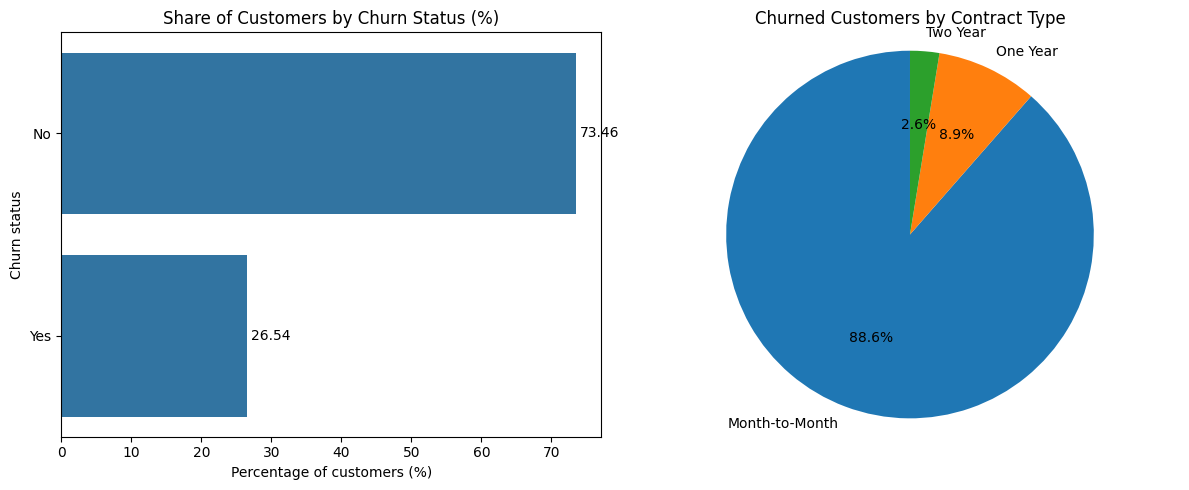

In [9]:
# ===== Overall churn rate and churned customers by contract type =====
churn_rate = (
    df_churn[TARGET_COL]
    .value_counts(normalize=True)
    .mul(100)
    .rename_axis(TARGET_COL)
    .reset_index(name="Percentage")
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_bar(
    data=churn_rate,
    x_col="Percentage",
    y_col=TARGET_COL,
    title="Share of Customers by Churn Status (%)",
    xlabel="Percentage of customers (%)",
    ylabel="Churn status",
    ax=axes[0],
)

# Composition of churned customers (not the churn rate per contract type)
plot_pie(
    data=df_churn[df_churn[TARGET_COL].eq("Yes")],
    column_name="Contract",
    title="Churned Customers by Contract Type",
    ax=axes[1],
)

plt.tight_layout()
plt.show()

**Insight 2: One in four customers churned, and almost all of them were on month-to-month contracts**

**Finding**
- 26.54% of customers churned and 73.46% stayed, a ratio of about 1 : 2.8.
- Among churned customers, 88.6% had a month-to-month contract, 8.9% a one-year contract and 2.6% a two-year contract.

**Fact check**
- Consistent with IBM's description of this sample, which highlights higher churn among month-to-month customers (IBM, 2019).

**Caveats**
- The pie chart shows the *composition* of churners, not the churn *rate* of each contract type. Its shares also depend on how many customers hold each contract. Insight 6 reports the actual rates.

**Modeling implication**
- The classes are imbalanced. Accuracy alone would be misleading (predicting "No" for everyone already scores 73.5%), so evaluation should focus on recall, precision and F1 for the churn class.
- The train/test split is stratified, and the training data is rebalanced (Section 5).

#### 4.4.3 Churn Rate by Customer Segment

**Demographics**

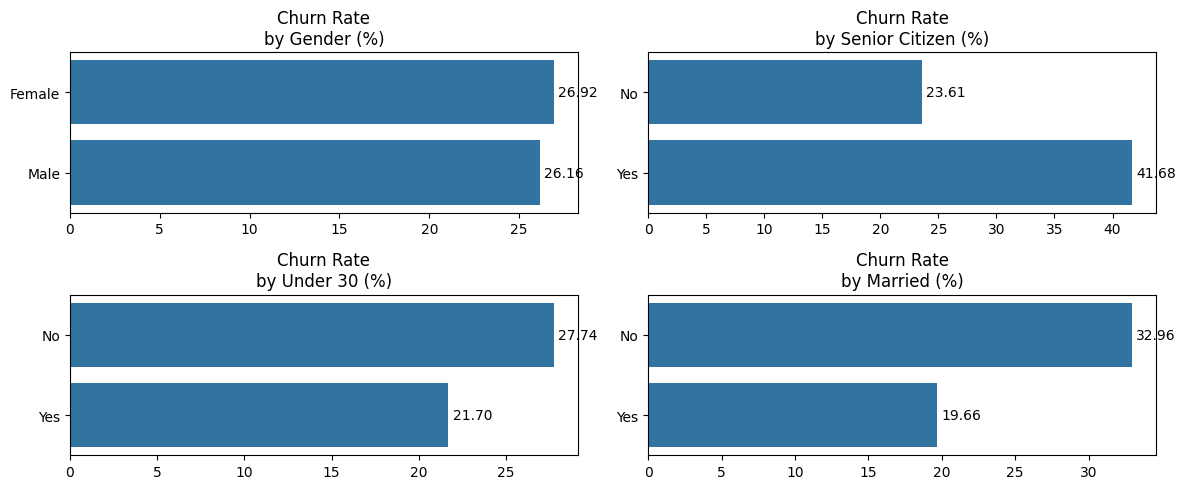

In [10]:
# ===== Churn rate by demographic attributes (excluding age and location) =====
demography_features = ["Gender", "Senior Citizen", "Under 30", "Married"]
plot_churn_rate_grid(df_churn, demography_features)

**Insight 3: Age and household situation matter; gender does not**

**Finding**
- Gender: 26.92% (female) vs 26.16% (male), a negligible gap.
- Senior citizens churn at 41.68% vs 23.61% for younger customers.
- Customers under 30 churn less (21.70%) than those aged 30 or older (27.74%).
- Unmarried customers churn at 32.96% vs 19.66% for married customers.

**Caveats**
- `Under 30` and `Senior Citizen` are both derived from `Age`, so they repeat information that `Age` already contains.
- Marital status may act through household size (dependents) or bundled family plans. The chart shows association, not cause.

**Modeling implication**
- Gender is unlikely to be useful; the chi-square test in Section 5.3.1 checks this formally.
- Age-derived flags are redundant for tree-based models but harmless.

**Location**

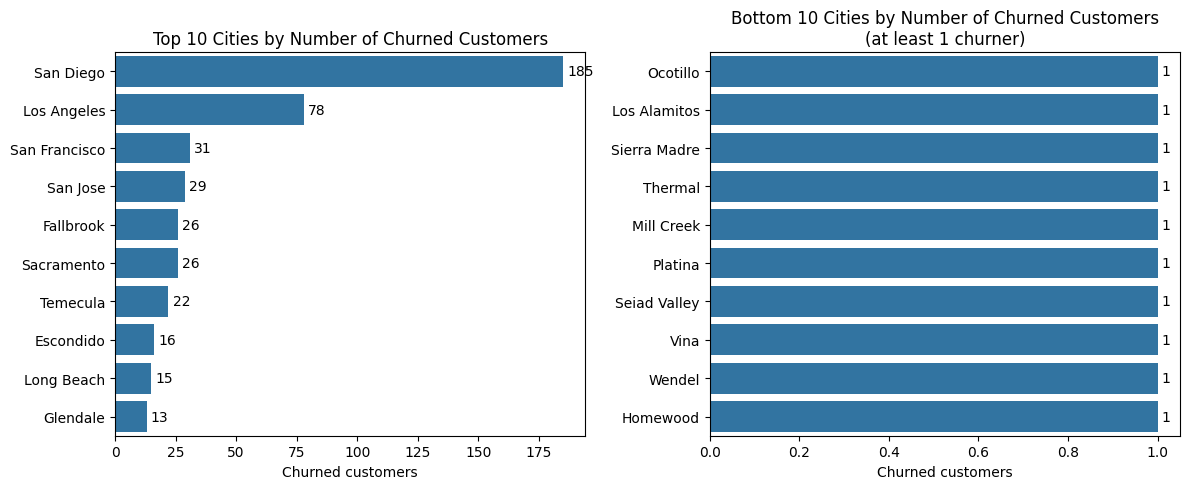

In [11]:
# ===== Number of churned customers per city (10 highest and 10 lowest) =====
# value_counts() only lists cities with at least one churned customer.
churn_count_by_city = (
    df_churn.loc[df_churn[TARGET_COL].eq("Yes"), "City"]
    .value_counts()
    .rename_axis("City")
    .reset_index(name="Churn Count")
)

top10_cities = churn_count_by_city.nlargest(10, "Churn Count")
bottom10_cities = churn_count_by_city.nsmallest(10, "Churn Count")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_bar(
    data=top10_cities,
    x_col="Churn Count",
    y_col="City",
    title="Top 10 Cities by Number of Churned Customers",
    xlabel="Churned customers",
    ax=axes[0],
    fmt="%d",
)

plot_bar(
    data=bottom10_cities,
    x_col="Churn Count",
    y_col="City",
    title="Bottom 10 Cities by Number of Churned Customers\n(at least 1 churner)",
    xlabel="Churned customers",
    ax=axes[1],
    fmt="%d",
)

plt.tight_layout()
plt.show()

**Insight 4: Churn counts by city mostly reflect city size**

**Finding**
- San Diego has by far the most churned customers (185), followed by Los Angeles (78), San Francisco (31) and San Jose (29).
- The "bottom 10" cities each have exactly one churned customer.

**Fact check**
- IBM's sample narrative deliberately includes a churn cluster in the San Diego area (IBM, 2019), so the San Diego spike is a designed feature of this synthetic dataset.

**Caveats**
- Raw counts scale with the number of customers in each city, so large cities rank high even at an average churn rate.
- Many cities are tied at one churner. Which ten appear in the bottom chart is therefore arbitrary and should not be interpreted.

**Follow-up check**
- Compare the *churn rate* per city, limited to cities with a minimum number of customers (e.g. ≥ 30), to see whether San Diego is truly above the 26.5% average.
- *Result:* among cities with at least 30 customers, San Diego has the highest churn rate, **64.9% (185 of 285 customers)**, followed by Fallbrook (60.5%) and Temecula (57.9%). San Diego is therefore far above the average, not only large.

**Modeling implication**
- `City` has many categories and few customers per city, so it is excluded from the features (Section 5.1). If location matters, a coarser region or a churn-rate encoding computed on the training data only would be safer.

**Products and services**

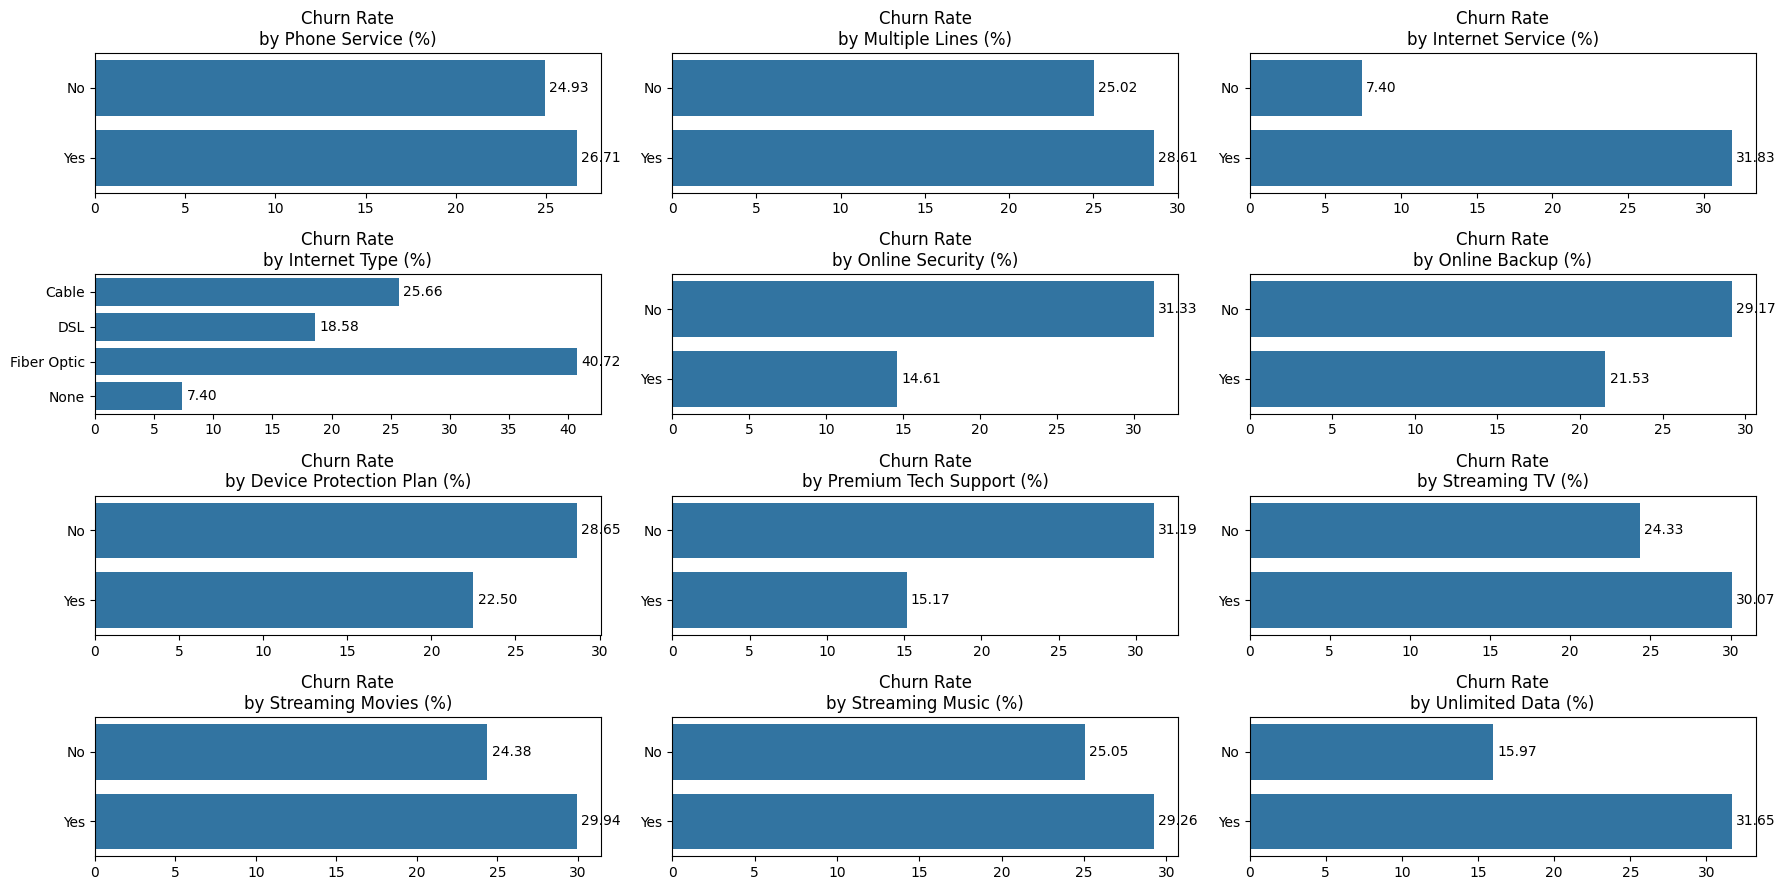

In [12]:
# ===== Churn rate by subscribed product or service =====
product_features = [
    "Phone Service", "Multiple Lines", "Internet Service",
    "Internet Type", "Online Security", "Online Backup",
    "Device Protection Plan", "Premium Tech Support", "Streaming TV",
    "Streaming Movies", "Streaming Music", "Unlimited Data",
]
plot_churn_rate_grid(df_churn, product_features, n_cols=3, figsize=(18, 9))

**Insight 5: Internet customers, especially fiber-optic users, churn most; protective add-ons go with lower churn**

**Finding**
- Internet subscribers churn at 31.83% vs 7.40% for customers without internet.
- By internet type: Fiber Optic 40.72%, Cable 25.66%, DSL 18.58%.
- Protective add-ons are associated with lower churn: Online Security 14.61% (with) vs 31.33% (without), Premium Tech Support 15.17% vs 31.19%, Online Backup 21.53% vs 29.17%, Device Protection Plan 22.50% vs 28.65%.
- Streaming services and Unlimited Data show the opposite pattern (e.g. Unlimited Data 31.65% vs 15.97%).
- Phone service makes little difference: 26.71% vs 24.93%.

**Caveats**
- **Confounding by internet subscription:** customers without internet automatically have "No" for every internet add-on, and they churn at only 7.40%. This pulls the "No" rate *down* for streaming and Unlimited Data, which is likely why those services appear to *increase* churn. Compare add-on users with non-users among internet subscribers only before drawing conclusions.
- The `Internet Type` panel shows customers without internet as a "None" category (7.40%), so all 7,043 customers are included.
- Add-ons are associated with lower churn, but customers who buy add-ons may already be more engaged. The data cannot show that selling add-ons *causes* lower churn.

**Follow-up check**
- Recompute the add-on churn rates for internet subscribers only.
- *Result:* among internet subscribers, the pattern for streaming and Unlimited Data **reverses**: churn is slightly *lower* with these services (e.g. Unlimited Data 31.7% with vs 32.9% without; Streaming TV 30.1% vs 33.5%). The protective add-ons keep the largest gaps: Online Security 14.6% with vs 41.8% without, Premium Tech Support 15.2% vs 41.6%. The apparent risk of streaming and Unlimited Data was confounding by internet subscription (computed in `app/models/eda.py`, tested in `tests/test_eda.py`).

**Business implication**
- Fiber-optic customers without security or tech-support add-ons are a natural first segment for retention campaigns, pending the follow-up check.

**Contract, offer and billing**

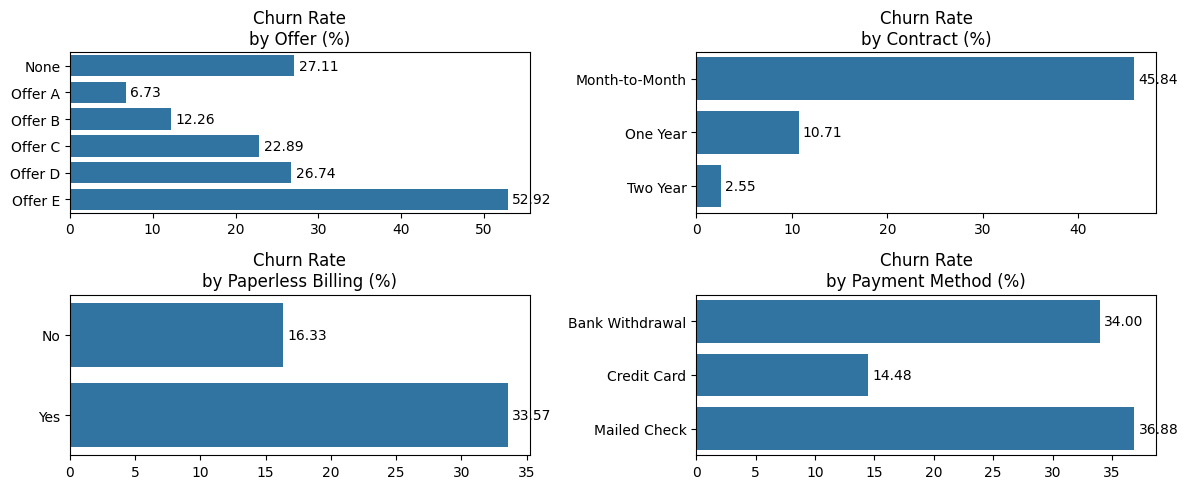

In [13]:
# ===== Churn rate by subscription and payment characteristics =====
subscription_payment_features = [
    "Offer", "Contract", "Paperless Billing", "Payment Method",
]
plot_churn_rate_grid(df_churn, subscription_payment_features)

**Insight 6: Contract length is the strongest churn signal**

**Finding**
- Contract: Month-to-Month 45.84%, One Year 10.71%, Two Year 2.55%. Month-to-month customers churn about 18 times more often than two-year customers.
- Offer: churn rises from Offer A (6.73%) to Offer E (52.92%).
- Paperless billing: 33.57% (Yes) vs 16.33% (No).
- Payment method: Mailed Check 36.88%, Bank Withdrawal 34.00%, Credit Card 14.48%.

**Caveats**
- 3,877 customers (55.0%) accepted no offer. They appear as the "None" bar (27.11%), which gives the offer comparison a baseline.
- Offers may be targeted at specific groups (e.g. new or low-tenure customers), so the Offer E churn rate may reflect *who received the offer* rather than the offer itself. This is a hypothesis to check against tenure.
- Payment method and paperless billing may proxy for other characteristics (e.g. age or contract type).

**Business implication**
- Moving month-to-month customers to longer contracts is the most promising retention lever suggested by the data. A controlled test would be needed to confirm the effect.

#### 4.4.4 Numerical Features

The charts below compare the distribution of each numerical feature for churned and retained customers. A *kernel density estimate (KDE)* is a smoothed histogram; each churn group is normalized separately, so the shapes can be compared despite the class imbalance.

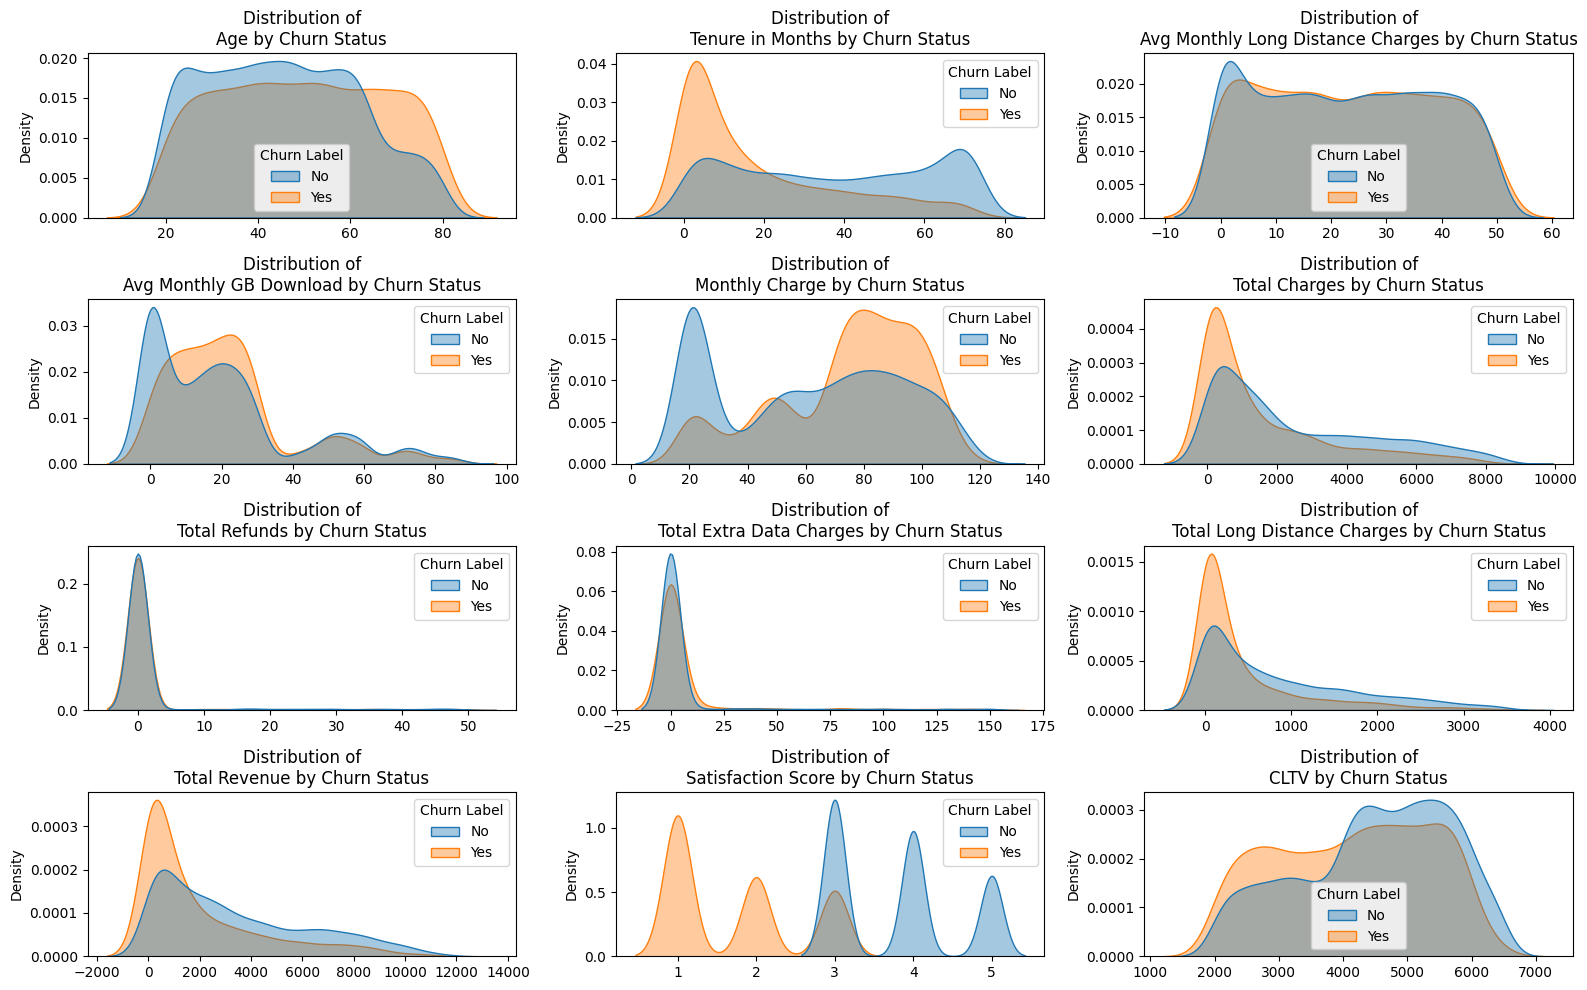

In [14]:
# ===== Distribution of numerical features by churn status =====
numerical_cols = [
    "Age", "Tenure in Months", "Avg Monthly Long Distance Charges",
    "Avg Monthly GB Download", "Monthly Charge", "Total Charges",
    "Total Refunds", "Total Extra Data Charges", "Total Long Distance Charges",
    "Total Revenue", "Satisfaction Score", "CLTV",
]

fig, axes = plt.subplots(4, 3, figsize=(16, 10))

for ax, col in zip(axes.flatten(), numerical_cols, strict=True):
    sns.kdeplot(
        data=df_churn,
        x=col,
        hue=TARGET_COL,
        hue_order=["No", "Yes"],
        common_norm=False,  # Normalize each group separately (classes are imbalanced)
        fill=True,
        alpha=0.4,
        ax=ax,
    )
    ax.set(title=f"Distribution of\n{col} by Churn Status", xlabel="", ylabel="Density")

plt.tight_layout()
plt.show()

**Reading the chart.** Churned and retained customers are overlaid, because a pattern among churners is only meaningful compared with non-churners. (An earlier version plotted churners only, with a line at the *mode*, which is not informative for continuous variables.)

Churned customers are concentrated in their first months of tenure, mostly pay 70–110 per month, are somewhat older, and only give satisfaction scores of 1–3, while retained customers spread across all tenures and score 3–5. Insight 7 quantifies these differences with the box plots below.

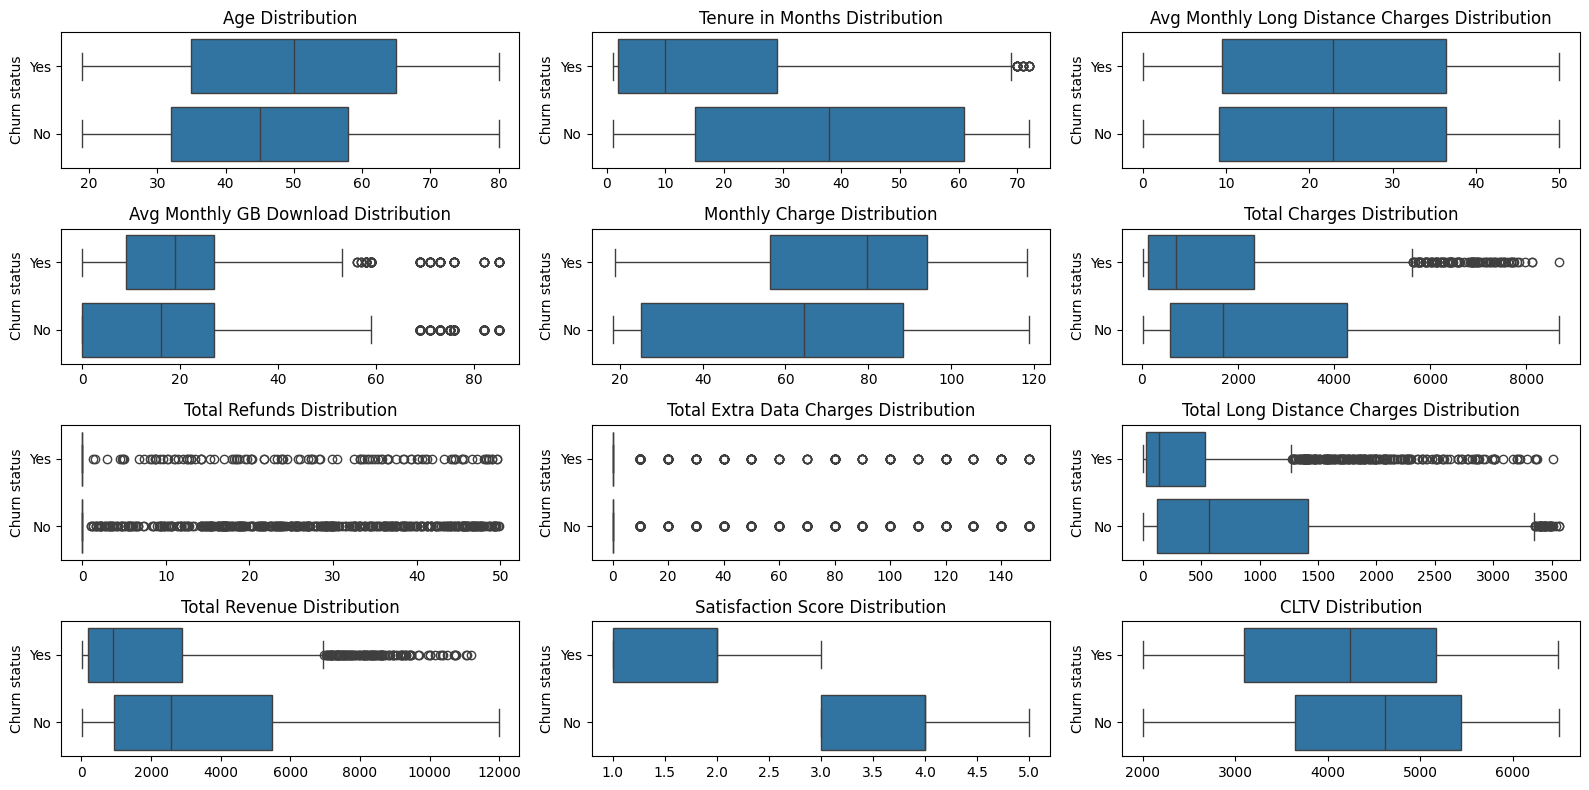

In [15]:
# ===== Box plots of numerical features by churn status (outlier check) =====
fig, axes = plt.subplots(4, 3, figsize=(16, 8))

for ax, col in zip(axes.flatten(), numerical_cols, strict=True):
    plot_box(
        data=df_churn,
        x_col=col,
        y_col=TARGET_COL,
        title=f"{col} Distribution",
        ylabel="Churn status",
        ax=ax,
    )

plt.tight_layout()
plt.show()

**Insight 7: Short tenure, higher monthly charges and low satisfaction separate churners from stayers**

**Finding** (approximate medians read from the box plots)
- Tenure: about 10 months for churners vs about 38 months for retained customers.
- Monthly charge: about 80 vs about 65.
- Age: about 50 vs about 45.
- CLTV: slightly lower for churners (about 4,250 vs 4,600).
- Avg Monthly Long Distance Charges: nearly identical distributions, so it carries little signal on its own.
- Satisfaction Score: churners score only 1–3; retained customers score 3–5. The two groups overlap only at score 3.

**Caveats**
- **Suspected leakage:** a satisfaction score that splits the classes almost perfectly is a warning sign. IBM does not document when the score is collected (IBM, 2019). If it is recorded after or during the cancellation process, it will not be available when the model must predict churn. The feature is therefore excluded by default (`EXCLUDE_SATISFACTION_SCORE = True`) until the timing is confirmed.
- **Zero-inflated features:** most customers have zero `Total Refunds` and zero `Total Extra Data Charges`. Their box collapses at 0, and *every* non-zero value is drawn as an outlier. These points are legitimate values, not errors.
- The totals (`Total Charges`, `Total Revenue`, `Total Long Distance Charges`) are right-skewed with long upper tails.

**Modeling implication**
- Outlier capping must skip zero-inflated columns, or they collapse into a constant (see Insight 10).
- Right-skewed totals are log-transformed in Section 5.3.3.

#### 4.4.5 Correlation between Numerical Features

*Pearson correlation (r)* measures how strongly two numerical variables move together in a straight-line relationship, from -1 to +1. Pairs with |r| ≥ 0.6 are treated as strongly *collinear* (carrying overlapping information).

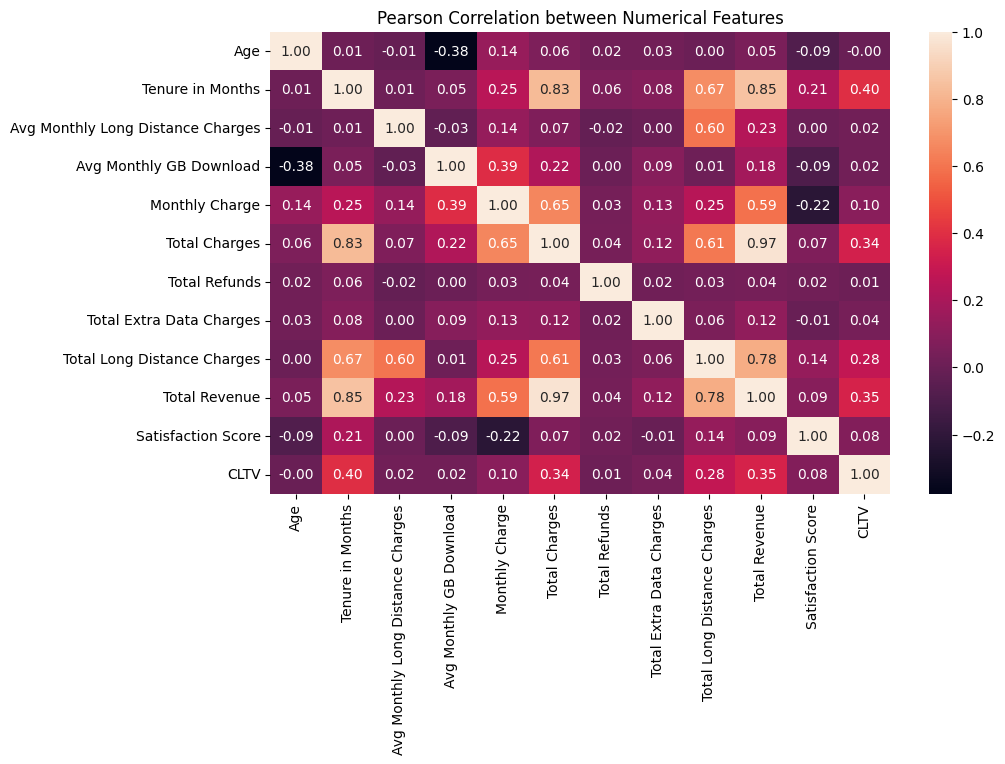

In [16]:
# ===== Pearson correlation heatmap =====
corr = df_churn[numerical_cols].corr()

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(corr, cmap="rocket", annot=True, fmt=".2f", ax=ax)
ax.set_title("Pearson Correlation between Numerical Features")
plt.show()

In [17]:
# ===== List strongly correlated feature pairs (|r| >= CORR_THRESHOLD) =====
# Keep only the upper triangle so each pair appears once and the diagonal is skipped.
upper_triangle_mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
feature_pairs = (
    corr.where(upper_triangle_mask)
    .rename_axis("Feature 1")
    .reset_index()
    .melt(id_vars="Feature 1", var_name="Feature 2", value_name="Pearson r")
    .dropna()
)
strong_pairs = feature_pairs[
    feature_pairs["Pearson r"].abs() >= CORR_THRESHOLD
].sort_values("Pearson r", key=abs, ascending=False)

print(f"Feature pairs with |r| >= {CORR_THRESHOLD}:")
display(strong_pairs.round(4).reset_index(drop=True))

Feature pairs with |r| >= 0.6:


,Feature 1,Feature 2,Pearson r
0,Total Charges,Total Revenue,0.9722
1,Tenure in Months,Total Revenue,0.8531
2,Tenure in Months,Total Charges,0.8261
3,Total Long Distance Charges,Total Revenue,0.7786
4,Tenure in Months,Total Long Distance Charges,0.6741
5,Monthly Charge,Total Charges,0.6512
6,Total Charges,Total Long Distance Charges,0.6102


**Insight 8: Billing totals are largely driven by tenure and overlap with each other**

**Finding**
- Seven pairs exceed |r| ≥ 0.6, all among billing and tenure features: Total Revenue–Total Charges (0.97), Tenure–Total Revenue (0.85), Tenure–Total Charges (0.83), Total Revenue–Total Long Distance Charges (0.78), Tenure–Total Long Distance Charges (0.67), Total Charges–Monthly Charge (0.65) and Total Long Distance Charges–Total Charges (0.61).
- Satisfaction Score shows only weak linear correlation with the other numerical features (|r| ≤ 0.22).

**Caveats**
- These correlations are largely mechanical rather than behavioral: cumulative totals grow with the number of months a customer has paid, and `Total Revenue` appears to aggregate the other charge columns. This is a hypothesis that can be verified directly.
- Pearson r only captures linear relationships and is sensitive to the skewed totals.

**Follow-up check**
- Test whether `Total Revenue ≈ Total Charges + Total Long Distance Charges + Total Extra Data Charges − Total Refunds` holds for every row.
- *Result:* confirmed. The identity holds for all 7,043 customers to the cent (`tests/test_eda.py`), so `Total Revenue` is an aggregate of the other charge columns, not independent information.

**Modeling implication**
- Gradient Boosting predictions are fairly robust to collinearity, but feature importance gets split among overlapping features. This notebook compresses the five collinear features with PCA (Section 5.3.7).

#### 4.4.6 EDA Summary

1. **Baseline.** 26.5% of customers churned in the quarter, a class ratio of about 1 : 2.8 (Insight 2). Churn is far above industry levels because the data is a synthetic stress scenario (Section 1).
2. **Drivers.** Contract type separates churn risk most clearly (month-to-month 45.8% vs two-year 2.6%). Risk is also high early in tenure (median about 10 months for churners vs about 38 for retained customers), for fiber-optic internet (40.7%), without online security or premium tech support (about 31%), for mailed-check and bank-withdrawal payers (36.9% and 34.0% vs 14.5% for credit card), for Offer E (52.9%) and for senior citizens (41.7%) (Insights 3, 5, 6 and 7).
3. **Leakage risks.** Churn reasons, churn category, customer status and churn score describe the outcome itself, and the satisfaction score separates the classes almost perfectly (Insights 1 and 7).
4. **Data properties.** Missing values are structural (Insight 1), refunds and extra data charges are zero-inflated, billing totals are right-skewed (Insight 7), and five billing and tenure features are strongly collinear (Insight 8).

### 4.5 From EDA to Data Preparation: Steps to Take

The EDA findings translate into concrete preparation decisions:

| EDA finding | Preparation decision | Section |
|---|---|---|
| Missing `Offer` and `Internet Type` mean "none" (Insight 1) | Fill with an explicit "No" category | 5.1 |
| Churn reason, churn category, customer status and churn score describe the outcome (Insights 1 and 7) | Remove as target leakage | 5.1 |
| Satisfaction score separates the classes almost perfectly (Insight 7) | Remove as suspected leakage (configurable) | 5.1 |
| Churn counts by city mostly reflect city size; geography has many unique values (Insight 4) | Remove identifiers and geography | 5.1 |
| Classes are imbalanced, 26.5% churn (Insight 2) | Stratified split; undersample the training split; evaluate with recall, precision and F1 | 5.2, 5.3.4, 2.4 |
| Gender and phone service show similar churn rates (Insights 3 and 5) | Chi-square screening on the training split | 5.3.1 |
| Refunds, extra data charges and dependents are zero-inflated (Insight 7) | Skip these columns when capping outliers | 5.3.2 |
| Billing totals are right-skewed (Insight 7) | Log-transform skewed columns | 5.3.3 |
| Five billing and tenure features are strongly collinear (Insight 8) | Compress them with PCA | 5.3.7 |

## 5. Data Preparation

This section turns the raw data into model-ready training and test splits. The guiding principle is to **prevent data leakage**: every step that *learns* something from the data (statistical tests, outlier limits, skewness, encoders, scalers, PCA) is fitted on the training split only and then applied unchanged to the test split. The test split thereby stays a fair simulation of new, unseen customers.

The section follows the CRISP-DM Data Preparation tasks, organised into four leakage-safe phases:

| CRISP-DM task | Where it happens |
|---|---|
| Select data | 5.1 attribute selection; 5.3.1 chi-square screening; 5.3.4 undersampling (row selection) |
| Clean data | 5.1 structural missing values; 5.3.2 outlier capping |
| Construct data | 5.3.3 log transformation; 5.3.7 principal components |
| Integrate data | Not required (a single source table) |
| Format data | 5.3.5 encoding; 5.3.6 standardization; 5.4 export |
| Generate test design *(a Modeling task)* | 5.2 stratified split; cross-validation folds (Section 6.2) |

### 5.1 Phase A: Before the Split

A feature may only be used if its value is known *at the moment the prediction is made*. Using information recorded after the outcome is called *data leakage*: the model looks excellent during development but fails in production (Kaufman et al., 2012). Each excluded group is checked against this rule.

- **Identifiers and geography** (`Customer ID`, `City`, `Zip Code`, coordinates, etc.): unique or near-unique values that do not generalize to new customers.
- **Target leakage** (`Customer Status`, `Churn Category`, `Churn Reason`): these describe the churn outcome itself; reasons are only recorded for customers who already left. `Churn Score` is the output of another churn model (IBM SPSS Modeler), so it would also leak the answer.
- **Suspected leakage: `Satisfaction Score`** (configurable in Section 3). Satisfaction is a well-established predictor of retention in telecom services when it is measured *before* the customer decides (Gustafsson et al., 2005; de Haan et al., 2015). In this dataset, three warning signs point the other way:
  1. The score separates the classes almost perfectly: churners score only 1–3 and retained customers only 3–5 (Insight 7). Survey-based studies find satisfaction to be an influential predictor, not a deterministic one.
  2. Every one of the 7,043 customers has a score. Complete coverage is unusual for a voluntary survey and suggests the value is derived or recorded at a process step every customer passes through, possibly the cancellation process (hypothesis).
  3. IBM's documentation describes the score but not when it is collected (IBM, 2019).

  The score is therefore excluded. If a score recorded *before* the prediction date becomes available (e.g. the most recent survey response), it can be added back as a legitimate feature.
- **Kept: referral behavior** (`Referred a Friend`, `Number of Referrals`). The original pipeline dropped these without a stated reason. They describe actions taken while the customer is still active, so they do not leak the outcome. Research supports their relevance: in a field experiment at a cellular telecom provider, customers who made a recommendation through a referral program defected at 7% within a year versus 19% in a matched control group (Garnefeld et al., 2013), and customers acquired through referrals show higher retention (Schmitt et al., 2011). They are therefore included as features (`INCLUDE_REFERRAL_FEATURES = True`). Note that `Referred a Friend` is simply `Number of Referrals > 0`, so the two columns overlap.

Missing `Offer` and `Internet Type` values are filled with "No" (Insight 1). Neither step uses statistics from the data, so it is safe to apply them before the split.

In [18]:
# ===== Drop non-feature columns and fill structural missing values =====
df_model = (
    df_churn
    .drop(columns=NON_FEATURE_COLS, errors="ignore")
    .fillna(value=STRUCTURAL_MISSING_FILL)
)

print(f"Columns kept (features + target): {df_model.shape[1]}")

Columns kept (features + target): 36


### 5.2 Phase B: Stratified Train/Test Split (Test Design)

In CRISP-DM, the test design belongs to the Modeling phase. It is fixed here, before any step that learns from data, so that Phase C can be fitted on the training split only.

The data is split into 80% training and 20% test data. *Stratification* keeps the churn ratio (about 26.5%) identical in both splits, so the test split is representative. A chronological split is not possible because the snapshot has no per-customer dates (Section 2.3).

In [19]:
# ===== Split into training and test sets =====
df_train, df_test = train_test_split(
    df_model,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=df_model[TARGET_COL],
)
df_train = df_train.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

print(f"Training set: {len(df_train):,} rows | Test set: {len(df_test):,} rows")

Training set: 5,634 rows | Test set: 1,409 rows


### 5.3 Phase C: Fitted on the Train Split Only

Every step below learns from data, so it is fitted on the training split only and then applied unchanged to the test split.

#### 5.3.1 Chi-square Screening of Categorical Features

The *chi-square test of independence* checks whether the distribution of a categorical feature differs between churned and retained customers. A p-value of 0.05 or higher means there is no statistically significant association, so the feature is dropped. The test runs on the training set only.

In [20]:
# ===== Chi-square test of independence (training set only) =====
candidate_cat_cols = (
    df_train.select_dtypes(include=["object", "string"])
    .columns.drop(TARGET_COL)
    .tolist()
)

chi2_results = []
for col in candidate_cat_cols:
    contingency_table = pd.crosstab(df_train[TARGET_COL], df_train[col])
    chi2_stat, p_value, _, _ = chi2_contingency(contingency_table)
    chi2_results.append({"Feature": col, "Chi2": chi2_stat, "p-value": p_value})

df_chi2 = pd.DataFrame(chi2_results).sort_values("p-value", ascending=False)
independent_cols = df_chi2.loc[df_chi2["p-value"] >= ALPHA, "Feature"].tolist()

display(df_chi2.round(4).reset_index(drop=True))
print(f"Independent of churn (p >= {ALPHA}), to be dropped: {independent_cols}")

,Feature,Chi2,p-value
0,Gender,0.4930,0.4826
1,Phone Service,0.8479,0.3571
2,Multiple Lines,7.9719,0.0048
3,Streaming Music,11.4216,0.0007
4,Under 30,17.0943,0.0000
5,Streaming Movies,19.3185,0.0000
6,Streaming TV,21.1779,0.0000
7,Device Protection Plan,29.6987,0.0000
8,Online Backup,31.9665,0.0000
9,Senior Citizen,126.7627,0.0000


Independent of churn (p >= 0.05), to be dropped: ['Gender', 'Phone Service']


**Insight 9: Only gender and phone service are unrelated to churn**

The test above runs on the training split only, after the identifier, geography and leakage columns were removed in Section 5.1.

**Finding**
- `Gender` (p = 0.48) and `Phone Service` (p = 0.36) are not associated with churn and are dropped. This matches the near-identical churn rates in Insights 3 and 5.
- All other 20 categorical features are associated with churn (p < 0.05); `Contract`, `Internet Type` and `Offer` have the largest test statistics.

**Caveats**
- An earlier version of this screening ran on the full dataset before the split and gave several misleading results, which are now fixed:
  - `Churn Category` and `Churn Reason` appeared "independent" (p = 1.00). This was an artifact: `pd.crosstab` drops missing values, and these columns are missing for every retained customer, so only churners were tested. They are now removed explicitly as target leakage (Section 5.1).
  - `Customer ID`, `Country`, `State` and `Quarter` were also "tested". A unique ID or a column with a single value cannot be meaningfully tested; these are now removed in Section 5.1.
  - The dropped features were labelled "p < 0.05", although they were dropped because p ≥ 0.05. The output above uses the correct label.
- With about 5,600 training rows, even weak associations become significant. The p-value shows whether an association exists, not how strong it is.

**Modeling implication**
- `Gender` and `Phone Service` are dropped, leaving 34 columns (33 features and the target).

In [21]:
# ===== Drop features that are statistically independent of churn =====
df_train = df_train.drop(columns=independent_cols)
df_test = df_test.drop(columns=independent_cols)

print(f"Remaining columns (features + target): {df_train.shape[1]}")

Remaining columns (features + target): 34


In [22]:
# ===== Verify that no missing values remain =====
for split_name, frame in {"training": df_train, "test": df_test}.items():
    n_missing = int(frame.isna().sum().sum())
    assert n_missing == 0, f"The {split_name} set still has {n_missing} missing values."

print("No missing values remain in the training or test set.")

No missing values remain in the training or test set.


#### 5.3.2 Outlier Capping (Winsorization)

*Winsorization* caps extreme values at a lower and upper limit instead of deleting rows. The limits follow Tukey's rule: 1.5 × the *interquartile range (IQR)* below the 25th percentile and above the 75th percentile. Limits are computed on the training set and saved, so the same caps can be applied to new customers in the Streamlit app.

Two groups of columns are skipped:
- **Zero-inflated columns** (IQR = 0, e.g. `Total Refunds`): capping would turn every non-zero value into 0 and erase the feature (Insight 10).
- **Ordinal rating scales** (`Satisfaction Score`, if enabled): every value on a 1–5 scale is valid.

In [23]:
# ===== Winsorization with IQR limits learned from the training set =====
def compute_iqr_bounds(
    df: pd.DataFrame,
    columns: list[str],
    multiplier: float = IQR_MULTIPLIER,
) -> dict[str, tuple[float, float]]:
    """Compute Tukey outlier limits for each column.

    Columns with an interquartile range of zero are skipped, because capping
    them would turn the column into a constant (all values set to the median).

    Args:
        df: Training data used to learn the limits.
        columns: Numerical columns to inspect.
        multiplier: Distance from the quartiles, in IQRs, at which values are capped.

    Returns:
        Mapping ``{column: (lower_limit, upper_limit)}`` for cappable columns.
    """
    bounds = {}
    for col in columns:
        q1, q3 = df[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        if iqr == 0:
            continue
        bounds[col] = (q1 - multiplier * iqr, q3 + multiplier * iqr)
    return bounds


def clip_to_bounds(
    df: pd.DataFrame,
    bounds: dict[str, tuple[float, float]],
) -> pd.DataFrame:
    """Cap each column at previously learned limits.

    Args:
        df: Data to transform (training, test or new customers).
        bounds: Limits returned by :func:`compute_iqr_bounds`.

    Returns:
        A copy of ``df`` with values outside the limits set to the nearest limit.
    """
    df = df.copy()
    for col, (lower, upper) in bounds.items():
        df[col] = df[col].clip(lower=lower, upper=upper)
    return df


num_feature_cols = df_train.select_dtypes(include="number").columns.tolist()
continuous_cols = [col for col in num_feature_cols if col not in ORDINAL_COLS]

outlier_bounds = compute_iqr_bounds(df_train, continuous_cols)
df_train = clip_to_bounds(df_train, outlier_bounds)
df_test = clip_to_bounds(df_test, outlier_bounds)
joblib.dump(outlier_bounds, PREPROCESSING_DIR / "outlier_bounds.joblib")

skipped_cols = [col for col in continuous_cols if col not in outlier_bounds]
print(f"Capped columns: {list(outlier_bounds)}")
print(f"Skipped (IQR = 0, zero-inflated): {skipped_cols}")

Capped columns: ['Age', 'Number of Referrals', 'Tenure in Months', 'Avg Monthly Long Distance Charges', 'Avg Monthly GB Download', 'Monthly Charge', 'Total Charges', 'Total Long Distance Charges', 'Total Revenue', 'CLTV']
Skipped (IQR = 0, zero-inflated): ['Number of Dependents', 'Total Refunds', 'Total Extra Data Charges']


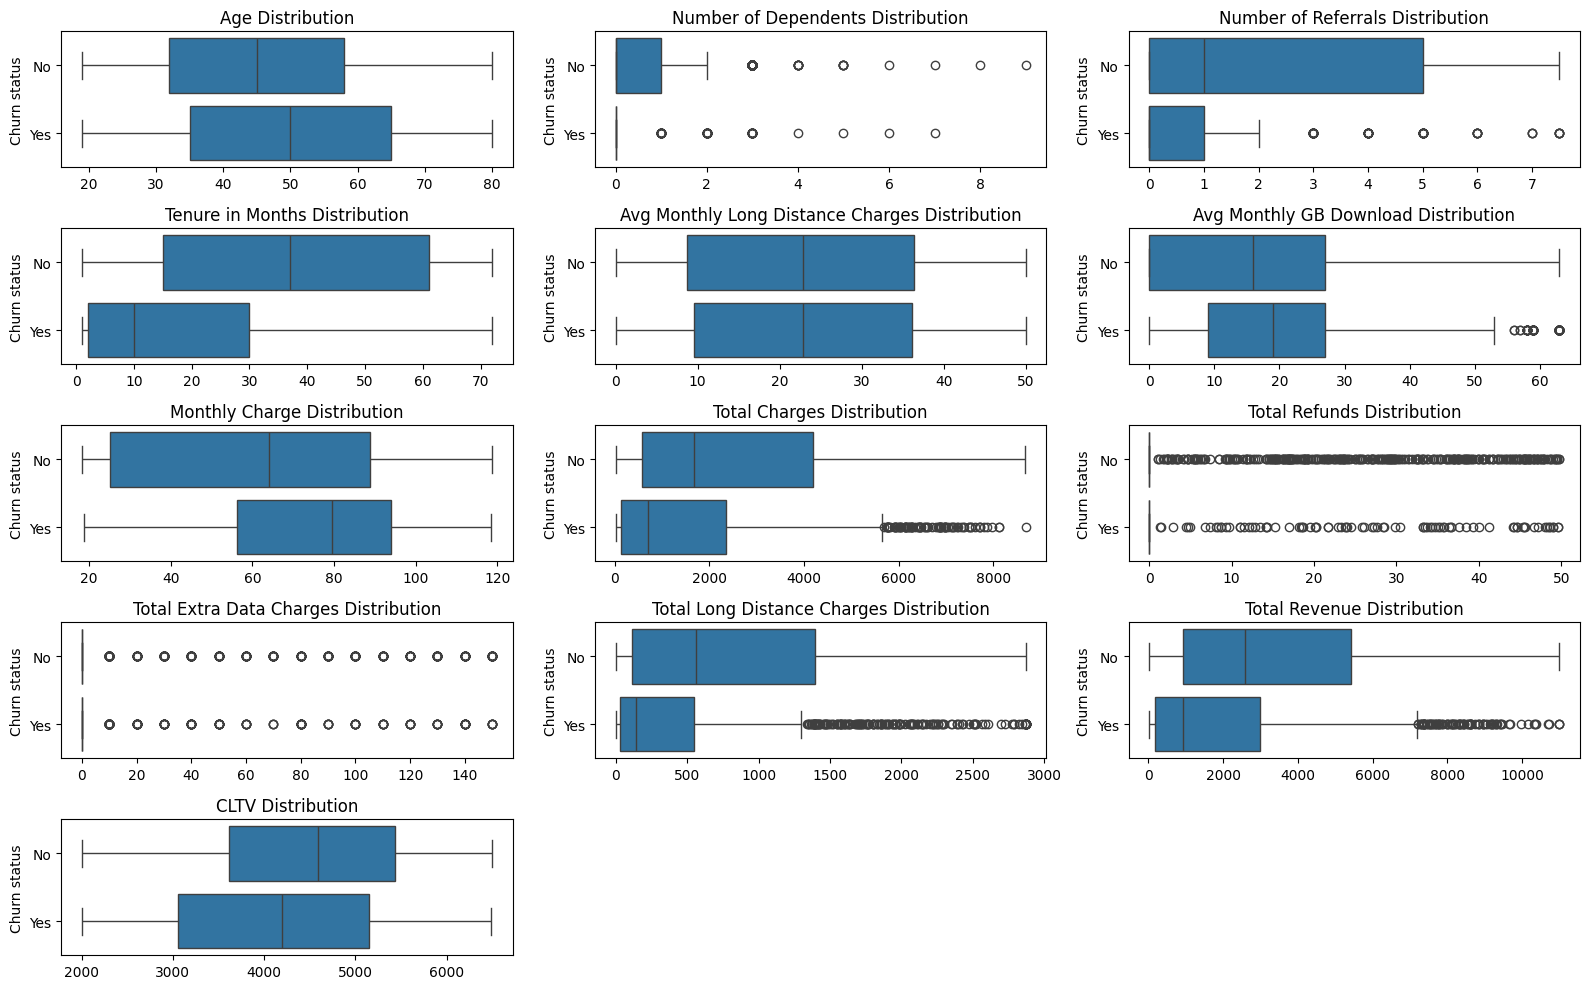

In [24]:
# ===== Box plots after winsorization (training set) =====
n_grid_cols = 3
n_grid_rows = math.ceil(len(num_feature_cols) / n_grid_cols)
fig, axes = plt.subplots(n_grid_rows, n_grid_cols, figsize=(16, 2 * n_grid_rows))
axes = axes.flatten()

for ax, col in zip(axes, num_feature_cols, strict=False):
    plot_box(
        data=df_train,
        x_col=col,
        y_col=TARGET_COL,
        title=f"{col} Distribution",
        ylabel="Churn status",
        ax=ax,
    )

for ax in axes[len(num_feature_cols):]:  # Hide unused grid cells
    ax.axis("off")

plt.tight_layout()
plt.show()

**Insight 10: Capping now keeps the zero-inflated features intact**

**Finding**
- Ten continuous features are capped with limits learned from the training split. `Number of Dependents`, `Total Refunds` and `Total Extra Data Charges` are skipped (IQR = 0), and the chart above shows that they keep their non-zero values.

**Caveats**
- An earlier version applied the IQR rule to every numerical column of the full dataset. Because most customers have a value of 0 in the three zero-inflated columns, both quartiles were 0 and every non-zero value was capped to 0, which turned these columns into constants and silently discarded refund, extra-data and household-size information. It also capped `Satisfaction Score` at 1.5, which is not a valid value on a 1–5 scale.
- The remaining points beyond the whiskers in the zero-inflated columns are legitimate values, not errors.

**Modeling implication**
- The three features carry information again and are log-transformed in Section 5.3.3 because of their skewness.

#### 5.3.3 Log Transformation of Skewed Features

*Skewness* measures how lopsided a distribution is; a long right tail (e.g. a few customers with very high total charges) gives a large positive value. `log1p` (the logarithm of 1 + x) compresses large values while keeping 0 at 0. Columns are selected based on the skewness of the training set.

In [25]:
# ===== Log-transform features with |skewness| > SKEW_THRESHOLD =====
skewness = df_train[continuous_cols].skew()
skewed = skewness[skewness.abs() > SKEW_THRESHOLD].sort_values(ascending=False)
log_transform_cols = skewed.index.tolist()

print(f"Features with |skewness| > {SKEW_THRESHOLD}:")
display(skewed.to_frame("Skewness"))

# log1p requires values > -1; all selected columns are non-negative charges,
# volumes or counts.
df_train[log_transform_cols] = np.log1p(df_train[log_transform_cols])
df_test[log_transform_cols] = np.log1p(df_test[log_transform_cols])
joblib.dump(log_transform_cols, PREPROCESSING_DIR / "log_transform_cols.joblib")

Features with |skewness| > 0.66:


,Skewness
Total Refunds,4.323804
Total Extra Data Charges,4.031703
Number of Dependents,2.128528
Number of Referrals,1.244272
Total Long Distance Charges,1.139271
Total Charges,0.975767
Avg Monthly GB Download,0.938451
Total Revenue,0.923665


['log_transform_cols.joblib']

Eight features exceed the threshold and are log-transformed. They include the three zero-inflated features that capping now keeps (`Total Refunds`, `Total Extra Data Charges`, `Number of Dependents`), which are the most skewed (skewness 2.1–4.3). The 0.66 threshold is a project choice; values between 0.5 and 1 are common rules of thumb.

In [26]:
# ===== Sanity check: size and churn rate of each set before resampling =====
split_summary = pd.DataFrame(
    {
        "Rows": [len(df_train), len(df_test)],
        "Churn rate (%)": [
            df_train[TARGET_COL].eq("Yes").mean() * 100,
            df_test[TARGET_COL].eq("Yes").mean() * 100,
        ],
    },
    index=["Training", "Test"],
).round(2)

display(split_summary)

,Rows,Churn rate (%)
Training,5634,26.54
Test,1409,26.54


#### 5.3.4 Random Undersampling of the Training Split

*Undersampling* randomly removes customers from the majority class ("No") until both classes are equally large, so the model does not learn to favor the majority. Only the training set is resampled; the test set keeps the real-world churn ratio, so evaluation reflects actual conditions.

In [27]:
# ===== Undersample the majority class (training set only) =====
def undersample_majority(
    df: pd.DataFrame,
    target_col: str,
    random_state: int = RANDOM_STATE,
) -> pd.DataFrame:
    """Balance classes by randomly sampling every class down to the minority size.

    Args:
        df: Training data.
        target_col: Name of the class label column.
        random_state: Seed for reproducible sampling.

    Returns:
        A shuffled DataFrame with an equal number of rows per class.
    """
    n_minority = df[target_col].value_counts().min()
    balanced = df.groupby(target_col, group_keys=False).sample(
        n=n_minority, random_state=random_state
    )
    return balanced.sample(frac=1, random_state=random_state).reset_index(drop=True)


df_train_undersampled = undersample_majority(df_train, TARGET_COL)

print("Training class distribution after undersampling:")
print(df_train_undersampled[TARGET_COL].value_counts())

Training class distribution after undersampling:
Churn Label
No     1495
Yes    1495
Name: count, dtype: int64


Undersampling discards about 2,600 retained customers (roughly 47% of the training data). Alternatives that keep all data, such as class weights in the Gradient Boosting model, are worth comparing during modeling.

#### 5.3.5 Encoding Categorical Features and the Target

Machine learning models need numbers. *One-hot encoding* turns each category into its own 0/1 column (for example, `Contract_Two Year`). The test set is aligned to the training columns: a category that never appears in the test set gets a column of zeros. The list of final column names is saved so the Streamlit app can build inputs in the same order.

In [28]:
# ===== One-hot encode categorical predictors =====
def one_hot_encode(
    df_train: pd.DataFrame,
    df_test: pd.DataFrame,
    columns: list[str],
    output_dir: Path = PREPROCESSING_DIR,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """One-hot encode categorical columns and align the test set to the training schema.

    The resulting column list is saved as ``predictor_encoder.joblib`` so that
    new data can be reindexed to the same schema at inference time.

    Args:
        df_train: Training data.
        df_test: Test data.
        columns: Categorical columns to encode.
        output_dir: Folder where the column list is saved.

    Returns:
        Encoded training and test data with identical columns.
    """
    train_encoded = pd.get_dummies(df_train, columns=columns, dtype=int)
    test_encoded = pd.get_dummies(df_test, columns=columns, dtype=int)
    # Categories unseen in training are dropped; missing ones are filled with 0.
    test_encoded = test_encoded.reindex(columns=train_encoded.columns, fill_value=0)

    feature_schema = train_encoded.columns.tolist()
    joblib.dump(feature_schema, output_dir / "predictor_encoder.joblib")
    return train_encoded, test_encoded


categorical_cols = (
    df_train_undersampled.select_dtypes(include=["object", "string"])
    .columns.drop(TARGET_COL)
    .tolist()
)

df_train_new, df_test_new = one_hot_encode(
    df_train=df_train_undersampled,
    df_test=df_test,
    columns=categorical_cols,
)

In [29]:
# ===== Encode the target: No -> 0, Yes -> 1 =====
target_encoder = LabelEncoder()
df_train_new[TARGET_COL] = target_encoder.fit_transform(df_train_new[TARGET_COL])
df_test_new[TARGET_COL] = target_encoder.transform(df_test_new[TARGET_COL])
joblib.dump(target_encoder, PREPROCESSING_DIR / "target_encoder.joblib")

class_mapping = {label: code for code, label in enumerate(target_encoder.classes_)}
print(f"Target mapping: {class_mapping}")

Target mapping: {'No': 0, 'Yes': 1}


#### 5.3.6 Standardization

*Standardization* rescales each numerical feature to a mean of 0 and a standard deviation of 1, using statistics from the training set. One scaler per column is saved (`<column>_scaler.joblib`) for reuse at inference time.

Tree-based models such as Gradient Boosting do not require scaling. The step is kept here because PCA in Section 5.3.7 does require it.

In [30]:
# ===== Standardize numerical features (fit on training data only) =====
def standardize_columns(
    df_train: pd.DataFrame,
    df_test: pd.DataFrame,
    columns: list[str],
    output_dir: Path = PREPROCESSING_DIR,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Standardize columns with one StandardScaler per column.

    Each scaler is fitted on the training data, applied to both sets and saved
    as ``<column>_scaler.joblib``.

    Args:
        df_train: Training data.
        df_test: Test data.
        columns: Numerical columns to standardize.
        output_dir: Folder where the fitted scalers are saved.

    Returns:
        Standardized copies of the training and test data.
    """
    df_train, df_test = df_train.copy(), df_test.copy()
    for col in columns:
        scaler = StandardScaler()
        # NumPy input keeps the scalers compatible with the existing inference code.
        df_train[col] = scaler.fit_transform(df_train[[col]].to_numpy()).ravel()
        df_test[col] = scaler.transform(df_test[[col]].to_numpy()).ravel()
        joblib.dump(scaler, output_dir / f"{col}_scaler.joblib")
    return df_train, df_test


df_train_new, df_test_new = standardize_columns(
    df_train=df_train_new,
    df_test=df_test_new,
    columns=num_feature_cols,
)

#### 5.3.7 Dimensionality Reduction with PCA

*Principal Component Analysis (PCA)* replaces several correlated features with a smaller number of uncorrelated *components* that retain most of their combined variation. It is applied only to the five collinear billing and tenure features identified in Insight 8. The chart shows how much variation each component explains.

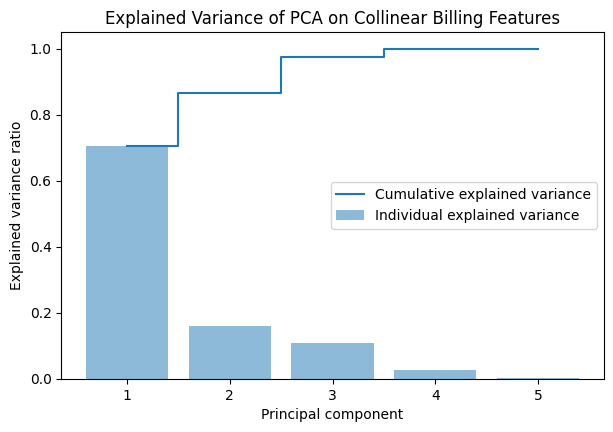

In [31]:
# ===== Explained variance of all possible components (training set) =====
pca_explorer = PCA(random_state=RANDOM_STATE).fit(df_train_new[PCA_COLS])
var_exp = pca_explorer.explained_variance_ratio_
cum_var_exp = np.cumsum(var_exp)
component_idx = np.arange(1, len(PCA_COLS) + 1)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(component_idx, var_exp, alpha=0.5, label="Individual explained variance")
ax.step(component_idx, cum_var_exp, where="mid", label="Cumulative explained variance")
ax.set(
    title="Explained Variance of PCA on Collinear Billing Features",
    xlabel="Principal component",
    ylabel="Explained variance ratio",
    xticks=component_idx,
)
ax.legend(loc="best")
plt.show()

**Insight 11: Two components keep about 86% of the variation in the five billing features**

**Finding**
- The first component explains about 70% of the variation, the second about 16%, and the third about 11%.
- Two components retain about 86–87% in total; three would retain about 97%.

**Caveats**
- The remaining ~13% of variation is discarded, which may include useful signal (e.g. the difference between monthly and total charges).
- Components are mixtures of the original features, so they are harder to explain to business users than "tenure" or "monthly charge". This matters for a Streamlit app that should explain *why* a customer is at risk.
- Gradient Boosting does not require uncorrelated inputs.

**Modeling implication**
- Keeping two components follows the original design. During modeling, compare it with (a) three components and (b) no PCA on the original features, and choose based on test recall and interpretability.

In [32]:
# ===== Replace the collinear features with principal components =====
def replace_with_components(
    df: pd.DataFrame,
    fitted_pca: PCA,
    columns: list[str],
    component_names: list[str],
) -> pd.DataFrame:
    """Swap a group of columns for their principal components.

    Args:
        df: Data containing ``columns``.
        fitted_pca: PCA already fitted on the training data.
        columns: Columns to compress and then drop.
        component_names: Names of the new component columns.

    Returns:
        A copy of ``df`` without ``columns`` and with the components appended.
    """
    components = pd.DataFrame(
        fitted_pca.transform(df[columns]), columns=component_names
    )
    df = df.drop(columns=columns).reset_index(drop=True)
    return pd.concat([df, components], axis=1)


pca = PCA(n_components=N_PCA_COMPONENTS, random_state=RANDOM_STATE)
pca.fit(df_train_new[PCA_COLS])
joblib.dump(pca, PREPROCESSING_DIR / "pca.joblib")

pc_names = [f"Pc_{i}" for i in range(1, N_PCA_COMPONENTS + 1)]
df_train_pca = replace_with_components(df_train_new, pca, PCA_COLS, pc_names)
df_test_pca = replace_with_components(df_test_new, pca, PCA_COLS, pc_names)

retained = pca.explained_variance_ratio_.sum()
print(f"Variance retained by {N_PCA_COMPONENTS} components: {retained:.1%}")

Variance retained by 2 components: 86.7%


In [33]:
# ===== Preview the processed training set =====
df_train_pca.head()

,Age,Number of Dependents,Number of Referrals,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Total Refunds,Total Extra Data Charges,Churn Label,CLTV,Under 30_No,...,Contract_Month-to-Month,Contract_One Year,Contract_Two Year,Paperless Billing_No,Paperless Billing_Yes,Payment Method_Bank Withdrawal,Payment Method_Credit Card,Payment Method_Mailed Check,Pc_1,Pc_2
0,0.136162,-0.434365,-0.725933,-0.906392,0.607540,-0.270282,-0.349,0,1.282988,1,...,1,0,0,0,1,1,0,0,1.712778,-0.478696
1,0.427630,-0.434365,-0.725933,-0.626298,-1.927391,-0.270282,-0.349,1,0.020830,1,...,1,0,0,0,1,0,0,1,-3.841473,-0.624012
2,1.826679,-0.434365,-0.725933,1.573143,0.688576,-0.270282,-0.349,1,-0.812513,1,...,1,0,0,0,1,1,0,0,-0.247353,1.395350
3,-0.388482,-0.434365,-0.725933,-0.217776,0.205094,-0.270282,-0.349,0,1.344128,1,...,0,0,1,1,0,0,1,0,3.153760,0.427897
4,-0.213601,-0.434365,0.201384,0.751579,0.516950,-0.270282,-0.349,1,0.390181,1,...,1,0,0,0,1,1,0,0,1.224872,1.017794


In [34]:
# ===== Preview the processed test set =====
df_test_pca.head()

,Age,Number of Dependents,Number of Referrals,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Total Refunds,Total Extra Data Charges,Churn Label,CLTV,Under 30_No,...,Contract_Month-to-Month,Contract_One Year,Contract_Two Year,Paperless Billing_No,Paperless Billing_Yes,Payment Method_Bank Withdrawal,Payment Method_Credit Card,Payment Method_Mailed Check,Pc_1,Pc_2
0,-0.796538,-0.434365,-0.725933,0.457288,-0.549293,-0.270282,-0.349,0,-1.867802,1,...,1,0,0,0,1,0,1,0,0.001577,0.466917
1,1.068861,-0.434365,-0.725933,-1.158734,0.607540,-0.270282,-0.349,1,-0.408823,1,...,1,0,0,0,1,1,0,0,-0.819307,0.823781
2,-0.271894,1.212830,1.128701,0.354028,0.155455,-0.270282,-0.349,0,1.012466,1,...,0,0,1,0,1,0,1,0,2.613636,-0.162429
3,-1.612650,-0.434365,-0.725933,-1.021269,1.065930,-0.270282,-0.349,1,-0.336796,0,...,1,0,0,0,1,1,0,0,-2.350488,1.404180
4,1.418623,-0.434365,-0.725933,0.748998,0.662501,-0.270282,-0.349,0,0.390181,1,...,0,1,0,0,1,0,1,0,2.375887,0.269613


### 5.4 Phase D: Model-Ready Datasets

The processed training and test splits are saved as CSV files. The prototype in Sections 6–7 uses the same datasets in memory. They are saved to `data/processed/`, where `pipelines/train.py` reads them for the tracked run (Section 8.2), and `test_pca.csv` is also used to generate sample payloads for the inference service.

In [35]:
# ===== Save the processed datasets =====
def save_to_csv(data: pd.DataFrame, file_path: Path) -> None:
    """Save a DataFrame to CSV without the index and report the result.

    Args:
        data: DataFrame to save.
        file_path: Destination path of the CSV file.
    """
    try:
        data.to_csv(file_path, index=False)
    except OSError as error:
        print(f"Failed to save {file_path}: {error}")
    else:
        print(f"Saved: {file_path} ({len(data):,} rows, {data.shape[1]} columns)")


save_to_csv(df_train_pca, PROCESSED_DIR / "train_pca.csv")
save_to_csv(df_test_pca, PROCESSED_DIR / "test_pca.csv")

Saved: train_pca.csv (2,990 rows, 59 columns)
Saved: test_pca.csv (1,409 rows, 59 columns)


## 6. Modelling

This section covers the CRISP-DM Modeling tasks: select the modelling technique (6.1), build the models (6.2–6.4), assess them on cross-validation (6.5), and turn predicted probabilities into a contact decision (6.6). It is a **prototype**: it runs in memory on the datasets from Section 5 so the design can be checked before the tracked, reproducible training run with MLflow (Section 8.2). The test design was fixed in Section 5.2, and the test split is not touched until Section 7.

**A known source of optimism.** The preprocessing in Section 5 was fitted on the whole training split before cross-validation, so each validation fold has already influenced the scalers and PCA. Cross-validation scores are therefore slightly optimistic. The test split is unaffected, which is why final judgements use Section 7 only.

### 6.1 Candidate Algorithms and Search Space

| Candidate | Why it is included |
|---|---|
| Logistic regression | Simple, interpretable baseline: if a linear model performs as well, the extra complexity of boosting is not justified |
| Gradient Boosting, default settings | Shows what the chosen algorithm achieves without tuning |
| Gradient Boosting, tuned with Optuna | The project's target model (Section 2.5) |

The tuning search space keeps the ranges of `pipelines/train.py`, expressed as continuous ranges so that Optuna can explore between the grid points:

| Hyperparameter | What it controls | Range |
|---|---|---|
| `n_estimators` | Number of trees | 50–200 |
| `learning_rate` | Contribution of each tree | 0.001–0.1 (log scale) |
| `max_depth` | Depth of each tree | 2–16 |
| `min_samples_split` | Minimum rows to split a node | 2–16 |
| `min_samples_leaf` | Minimum rows in a leaf | 1–8 |
| `subsample` | Share of rows used per tree | 0.6–1.0 |
| `max_features` | Features considered per split | all, square root, log2 |

In [36]:
# ===== Gradient Boosting search space for Optuna =====
def gb_search_space(trial: optuna.Trial) -> dict[str, object]:
    """Sample one Gradient Boosting configuration.

    The ranges mirror the grid in ``pipelines/train.py`` so that results from
    this prototype and from the tracked MLflow run stay comparable.

    Args:
        trial: Optuna trial that records the sampled values.

    Returns:
        Keyword arguments for ``GradientBoostingClassifier``.
    """
    return {
        "n_estimators": trial.suggest_int("n_estimators", 50, 200),
        "learning_rate": trial.suggest_float("learning_rate", 1e-3, 0.1, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 16),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 16),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 8),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "max_features": trial.suggest_categorical(
            "max_features", [None, "sqrt", "log2"]
        ),
    }

### 6.2 Training, Cross-Validation and Tuning Utilities

Every candidate is scored with the same **5-fold stratified cross-validation** on the balanced training split. Three scores are reported:

* **F2** (*F-beta with beta = 2*): combines precision and recall but weights recall twice as much, matching the recall-first criterion D3. It is the selection and tuning objective.
* **Recall:** the share of churners caught.
* **ROC-AUC:** how well the model ranks churners above non-churners, independent of any threshold.

Precision is not reported here: on balanced folds it overstates the precision the model would achieve at the real churn rate. Section 6.6 converts results back to the real churn rate.

In [37]:
# ===== Model inputs and cross-validation setup =====
X_train = df_train_pca.drop(columns=TARGET_COL)
y_train = df_train_pca[TARGET_COL]
X_test = df_test_pca.drop(columns=TARGET_COL)
y_test = df_test_pca[TARGET_COL]

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
f_beta_scorer = make_scorer(fbeta_score, beta=F_BETA)
CV_SCORING = {f"F{F_BETA}": f_beta_scorer, "Recall": "recall", "ROC-AUC": "roc_auc"}


def cross_validate_model(model, features: pd.DataFrame, target: pd.Series) -> pd.Series:
    """Score a model with the shared stratified cross-validation.

    Args:
        model: Unfitted scikit-learn classifier.
        features: Training features.
        target: Training target (1 = churn).

    Returns:
        Mean score per metric in ``CV_SCORING``.
    """
    scores = cross_validate(
        model, features, target, cv=cv, scoring=CV_SCORING, n_jobs=-1
    )
    return pd.Series({name: scores[f"test_{name}"].mean() for name in CV_SCORING})


print(
    f"Training rows: {len(X_train):,} | Test rows: {len(X_test):,} | "
    f"Features: {X_train.shape[1]}"
)

Training rows: 2,990 | Test rows: 1,409 | Features: 58


### 6.3 Baseline Models

Both baselines are trained with default settings and scored with the same cross-validation as the tuned model, so the effect of tuning can be measured without touching the test split.

In [38]:
# ===== Baseline models (default settings) =====
candidates = {
    "Logistic regression": LogisticRegression(max_iter=1_000),
    "Gradient Boosting (default)": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),
}
cv_results = {
    name: cross_validate_model(model, X_train, y_train)
    for name, model in candidates.items()
}
display(pd.DataFrame(cv_results).T.round(4))

,F2,Recall,ROC-AUC
Logistic regression,0.8426,0.8522,0.9056
Gradient Boosting (default),0.8372,0.8435,0.9076


### 6.4 Hyperparameter Tuning with Optuna

*Optuna* searches the hyperparameter space adaptively: its default sampler (TPE) proposes new configurations near those that scored well so far, which usually finds good settings with fewer trials than a random search (Akiba et al., 2019).

**Storage in flat files.** The study is stored in a journal file (`optuna/<study>.log`), an append-only log with one JSON record per line. If the notebook is interrupted, re-running the cell resumes the study instead of starting over. The study name includes a fingerprint of the training data, so a change in Section 5 starts a fresh study automatically. After tuning, all trials are exported to CSV and the best configuration to JSON, for the MLflow run and for review.

In [39]:
# ===== Optuna study: maximize cross-validated F2 =====
def objective(trial: optuna.Trial) -> float:
    """Return the mean cross-validated F-beta score of one configuration.

    Args:
        trial: Optuna trial that samples the hyperparameters.

    Returns:
        Mean F-beta score across the cross-validation folds.
    """
    model = GradientBoostingClassifier(
        random_state=RANDOM_STATE, **gb_search_space(trial)
    )
    scores = cross_validate(
        model, X_train, y_train, cv=cv, scoring=f_beta_scorer, n_jobs=-1
    )
    return float(scores["test_score"].mean())


# A new study is created whenever the training data changes.
data_fingerprint = hashlib.sha256(
    pd.util.hash_pandas_object(df_train_pca, index=True).to_numpy().tobytes()
).hexdigest()[:8]
study_name = f"{OPTUNA_STUDY_PREFIX}_{data_fingerprint}"

OPTUNA_DIR.mkdir(parents=True, exist_ok=True)
study = optuna.create_study(
    study_name=study_name,
    storage=JournalStorage(JournalFileBackend(str(OPTUNA_DIR / f"{study_name}.log"))),
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
    load_if_exists=True,  # resume instead of starting over
)
n_completed = sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials)
study.optimize(objective, n_trials=max(0, N_TRIALS - n_completed))

# Flat-file exports for review and for the tracked MLflow run
study.trials_dataframe().to_csv(OPTUNA_DIR / f"{study_name}_trials.csv", index=False)
best_params_path = OPTUNA_DIR / f"{study_name}_best_params.json"
best_params_path.write_text(
    json.dumps(
        {"best_cv_f_beta": study.best_value, "params": study.best_params}, indent=2
    )
)

print(
    f"Study {study_name}: {len(study.trials)} trials, "
    f"best CV F{F_BETA} = {study.best_value:.4f}"
)
print(f"Best parameters saved to {best_params_path}")

Study gb_churn_prototype_cf764beb: 50 trials, best CV F2 = 0.8508
Best parameters saved to optuna/gb_churn_prototype_cf764beb_best_params.json


### 6.5 Model Selection

Candidates are ranked by cross-validated F2. The tuned score is the best of `N_TRIALS` attempts and is therefore slightly optimistic compared with the baselines. If the tuned model does not clearly beat the default model or logistic regression, the simpler model is preferred. The selected model is then refitted on the whole balanced training split.

In [40]:
# ===== Compare candidates on cross-validation and refit the best one =====
candidates["Gradient Boosting (tuned)"] = GradientBoostingClassifier(
    random_state=RANDOM_STATE, **study.best_params
)
cv_results["Gradient Boosting (tuned)"] = cross_validate_model(
    candidates["Gradient Boosting (tuned)"], X_train, y_train
)

df_cv = pd.DataFrame(cv_results).T.sort_values(f"F{F_BETA}", ascending=False)
display(df_cv.round(4))

selected_name = df_cv.index[0]
selected_model = clone(candidates[selected_name]).fit(X_train, y_train)
print(f"Selected model: {selected_name}")

,F2,Recall,ROC-AUC
Gradient Boosting (tuned),0.8508,0.8622,0.9057
Logistic regression,0.8426,0.8522,0.9056
Gradient Boosting (default),0.8372,0.8435,0.9076


Selected model: Gradient Boosting (tuned)


### 6.6 Probability Correction and Decision Thresholds

**Why probabilities need correcting.** The model learned from a 50/50 training split, but only about 26.5% of real customers churn. Undersampling does not change how the model *ranks* customers, but it inflates their predicted probabilities (Dal Pozzolo et al., 2015). The correction below maps each probability *p* back to the real churn rate, where *β* is the share of non-churners kept by undersampling:

$$p_{\text{real}} = \frac{\beta \, p}{\beta \, p - p + 1}, \qquad \beta = \frac{n_{\text{churn}}}{n_{\text{no churn}}}$$

**Precision at the real churn rate.** On balanced folds, precision is overstated. Recall (the true positive rate, TPR) and the false positive rate (FPR) do not depend on the class mix, so precision at the real churn rate *π* is recomputed from them: precision = π·TPR / (π·TPR + (1 − π)·FPR).

**Two thresholds** are derived from out-of-fold predictions on the training split, so the test split stays untouched:

* **Recall threshold (used for criterion D3):** the threshold with the highest precision among those that keep recall ≥ 0.85.
* **Break-even threshold (campaign economics, Section 2.4):** contact a customer when the expected value of contacting is positive, i.e. when the corrected probability exceeds (d + f) / (γ·(CLV − d) + d).

Both thresholds are saved to `decision_policy.json`, so the Streamlit app applies exactly the same rule.

In [41]:
# ===== Correct probabilities and choose decision thresholds =====
def correct_for_undersampling(proba: np.ndarray, beta: float) -> np.ndarray:
    """Map probabilities of an undersampled model back to the real class mix.

    Args:
        proba: Churn probabilities from a model trained on balanced data.
        beta: Share of majority-class rows kept by undersampling
            (churners / non-churners in the original training split).

    Returns:
        Churn probabilities on the scale of the real churn rate.
    """
    return beta * proba / (beta * proba - proba + 1)


def rates_at_threshold(
    y_true: pd.Series, proba: np.ndarray, threshold: float, prior: float
) -> dict[str, float]:
    """Compute recall and precision at the real churn rate for one threshold.

    Args:
        y_true: True labels (1 = churn).
        proba: Corrected churn probabilities.
        threshold: Probability at or above which a customer is flagged.
        prior: Real churn rate.

    Returns:
        Recall, precision at the real churn rate, and the share of customers flagged.
    """
    flagged = proba >= threshold
    positives = y_true.to_numpy() == 1
    tpr = flagged[positives].mean()
    fpr = flagged[~positives].mean()
    denominator = prior * tpr + (1 - prior) * fpr
    return {
        "Recall (OOF)": tpr,
        "Precision at real churn rate (OOF)": prior * tpr / denominator
        if denominator
        else np.nan,
        "Customers flagged (%)": 100 * denominator,
    }


# Real churn rate in the training split before undersampling (Section 5.3.4)
churn_prior = df_train[TARGET_COL].eq("Yes").mean()
undersampling_beta = churn_prior / (1 - churn_prior)

oof_proba = cross_val_predict(
    selected_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]
oof_proba = correct_for_undersampling(oof_proba, undersampling_beta)

# (a) Recall threshold: highest precision among thresholds with recall >= TARGET_RECALL
fpr, tpr, thresholds = roc_curve(y_train, oof_proba, drop_intermediate=False)
with np.errstate(divide="ignore", invalid="ignore"):
    precision_at_prior = (
        churn_prior * tpr / (churn_prior * tpr + (1 - churn_prior) * fpr)
    )
eligible = (tpr >= TARGET_RECALL) & np.isfinite(thresholds)
recall_threshold = float(
    thresholds[np.nanargmax(np.where(eligible, precision_at_prior, np.nan))]
)

# (b) Break-even threshold from the illustrative campaign economics
clv_reference = df_churn.loc[df_churn[TARGET_COL].eq("Yes"), "CLTV"].median()
offer_cost = OFFER_COST_RATIO * clv_reference
contact_cost = CONTACT_COST_RATIO * clv_reference
breakeven_threshold = (offer_cost + contact_cost) / (
    OFFER_ACCEPTANCE_RATE * (clv_reference - offer_cost) + offer_cost
)

df_thresholds = pd.DataFrame(
    {
        name: {
            "Threshold": value,
            **rates_at_threshold(y_train, oof_proba, value, churn_prior),
        }
        for name, value in {
            "Recall threshold": recall_threshold,
            "Break-even threshold": breakeven_threshold,
        }.items()
    }
).T
display(df_thresholds.round(3))

decision_policy = {
    "model": selected_name,
    "churn_prior": churn_prior,
    "undersampling_beta": undersampling_beta,
    "recall_threshold": recall_threshold,
    "breakeven_threshold": breakeven_threshold,
    "target_recall": TARGET_RECALL,
    # Campaign economics, read by modelling_tuning.py for net value and break-even
    "clv_reference": clv_reference,
    "offer_cost": offer_cost,
    "contact_cost": contact_cost,
    "offer_acceptance_rate": OFFER_ACCEPTANCE_RATE,
}
policy_path = PROTOTYPE_DIR / "decision_policy.json"
policy_path.write_text(json.dumps(decision_policy, indent=2, default=float))
print(f"Decision policy saved to {policy_path}")

,Threshold,Recall (OOF),Precision at real churn rate (OOF),Customers flagged (%)
Recall threshold,0.268,0.852,0.608,37.14
Break-even threshold,0.164,1.000,0.265,100.00


238

## 7. Evaluation

The selected model is evaluated **once** on the held-out test split (Section 5.2) and compared with the naive benchmarks. Sections 7.1–7.7 assess the model technically, and Sections 7.8–7.10 complete the CRISP-DM Evaluation phase: assessment against the business and data-mining success criteria, review of the process, and the decision on next steps.

### 7.1 Evaluation Setup

* **Data:** the test split (about 1,409 customers) with the real churn ratio. It was never resampled or used for any choice in Section 6.
* **Probabilities:** corrected for undersampling (Section 6.6).
* **Decisions:** the recall threshold is the primary rule (criterion D3); the break-even threshold is reported for comparison.

### 7.2 Metric Definitions

The metrics follow Section 2.4. *Lift* compares precision with the churn rate of the test split: a lift of 2 means flagged customers churn twice as often as the average customer. *Net value* applies the illustrative campaign economics to the flagged customers, using their true outcome.

In [42]:
# ===== Metric helpers =====
def classification_metrics(
    y_true: pd.Series, y_pred: np.ndarray, proba: np.ndarray | None = None
) -> dict[str, float]:
    """Compute churn-class metrics for one set of predictions.

    Args:
        y_true: True labels (1 = churn).
        y_pred: Predicted labels (1 = flagged for contact).
        proba: Optional churn probabilities for the threshold-free metrics.

    Returns:
        Recall, precision, F1, F-beta, lift, share contacted and, if ``proba``
        is given, PR-AUC and ROC-AUC.
    """
    metrics = {
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        f"F{F_BETA}": fbeta_score(y_true, y_pred, beta=F_BETA, zero_division=0),
        "Contacted (%)": 100 * np.mean(y_pred),
    }
    metrics["Lift"] = metrics["Precision"] / y_true.mean()
    if proba is not None:
        metrics["PR-AUC"] = average_precision_score(y_true, proba)
        metrics["ROC-AUC"] = roc_auc_score(y_true, proba)
    return metrics


def campaign_net_value(y_true: pd.Series, y_pred: np.ndarray) -> float:
    """Return the expected net value of contacting the flagged customers.

    A contacted churner is retained with probability ``OFFER_ACCEPTANCE_RATE``;
    a contacted non-churner accepts the offer anyway. Every contact costs
    ``contact_cost`` (illustrative economics, Section 2.4).

    Args:
        y_true: True labels (1 = churn).
        y_pred: Predicted labels (1 = contacted).

    Returns:
        Expected net value in the currency units of ``CLTV``.
    """
    churned = y_true.to_numpy()[np.asarray(y_pred).astype(bool)]
    gains = OFFER_ACCEPTANCE_RATE * (clv_reference - offer_cost) * churned
    costs = offer_cost * (1 - churned) + contact_cost
    return float((gains - costs).sum())

### 7.3 Test-Set Predictions and Naive Benchmarks

* **Majority class** contacts no one. Its recall is 0, so any useful model must beat it.
* **Month-to-month rule** contacts every month-to-month customer. It is the harder benchmark, because contract type is the strongest single churn signal (Insight 6).

In [43]:
# ===== Predictions on the test split =====
test_proba = correct_for_undersampling(
    selected_model.predict_proba(X_test)[:, 1], undersampling_beta
)
MODEL_AT_RECALL = f"{selected_name} @ recall threshold"
MODEL_AT_BREAKEVEN = f"{selected_name} @ break-even threshold"

predictions = {
    "Majority class (contact no one)": np.zeros(len(y_test), dtype=int),
    "Month-to-month rule": X_test["Contract_Month-to-Month"].to_numpy().astype(int),
    MODEL_AT_RECALL: (test_proba >= recall_threshold).astype(int),
    MODEL_AT_BREAKEVEN: (test_proba >= breakeven_threshold).astype(int),
}

df_test_report = pd.DataFrame(
    {
        name: {
            **classification_metrics(
                y_test, y_pred, test_proba if name.startswith(selected_name) else None
            ),
            "Net value": campaign_net_value(y_test, y_pred),
        }
        for name, y_pred in predictions.items()
    }
).T
display(df_test_report.round(3))

,Recall,Precision,F1,F2,Contacted (%),Lift,Net value,PR-AUC,ROC-AUC
Majority class (contact no one),0.000,0.000,0.000,0.000,0.000,0.00,0.00,NaN,NaN
Month-to-month rule,0.920,0.470,0.622,0.772,51.952,1.77,317765.24,NaN,NaN
Gradient Boosting (tuned) @ recall threshold,0.885,0.605,0.719,0.810,38.822,2.28,342430.40,0.769,0.915
Gradient Boosting (tuned) @ break-even threshold,1.000,0.265,0.420,0.644,100.000,1.00,202555.21,0.769,0.915


### 7.4 Test-Set Performance and Success Criteria

The checks below compare the model at the recall threshold with criteria D3 and D4 and with the first part of B3. D4 is judged against the month-to-month rule **on the same test split**, so both are measured on identical customers.

In [44]:
# ===== Data-mining criteria on the test split =====
model_row = df_test_report.loc[MODEL_AT_RECALL]
rule_row = df_test_report.loc["Month-to-month rule"]

criteria_checks = pd.DataFrame(
    [
        (
            "D3",
            f"Recall >= {TARGET_RECALL}",
            model_row["Recall"],
            TARGET_RECALL,
            model_row["Recall"] >= TARGET_RECALL,
        ),
        (
            "D4",
            "Precision above the month-to-month rule",
            model_row["Precision"],
            rule_row["Precision"],
            model_row["Precision"] > rule_row["Precision"],
        ),
        (
            "D4",
            "F1 above the month-to-month rule",
            model_row["F1"],
            rule_row["F1"],
            model_row["F1"] > rule_row["F1"],
        ),
        (
            "B3 (part 1)",
            "Campaign net value above zero",
            model_row["Net value"],
            0.0,
            model_row["Net value"] > 0,
        ),
    ],
    columns=["ID", "Criterion", "Model", "Benchmark", "Met"],
)
display(criteria_checks.round(3))

,ID,Criterion,Model,Benchmark,Met
0,D3,Recall >= 0.85,0.885,0.850,True
1,D4,Precision above the month-to-month rule,0.605,0.470,True
2,D4,F1 above the month-to-month rule,0.719,0.622,True
3,B3 (part 1),Campaign net value above zero,342430.400,0.000,True


### 7.5 Confusion Matrix and Precision-Recall Curve

The confusion matrix shows how many churners are caught or missed at the recall threshold. The precision-recall curve shows the trade-off across all thresholds; the dashed line is the precision of contacting customers at random (the test churn rate).

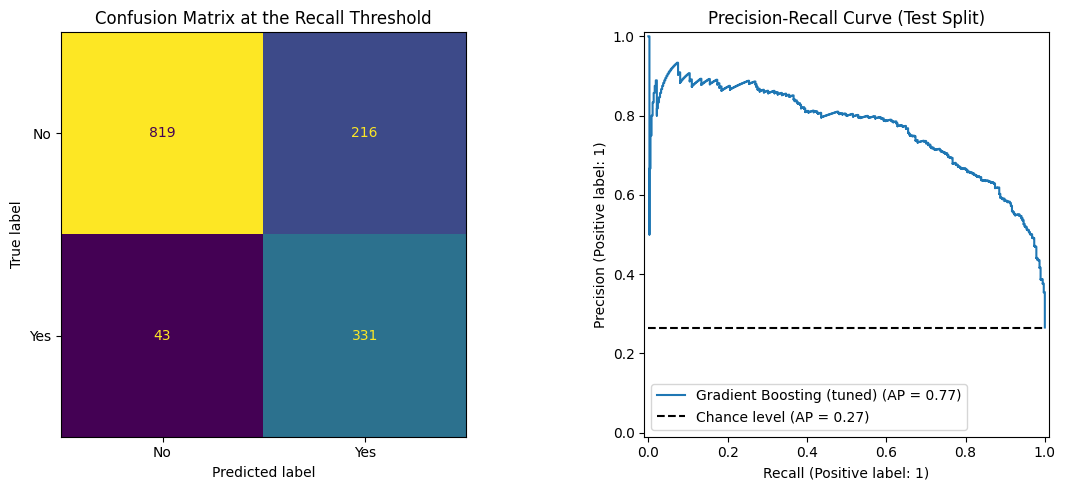

In [45]:
# ===== Confusion matrix and precision-recall curve (test split) =====
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions[MODEL_AT_RECALL],
    display_labels=target_encoder.classes_,
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Confusion Matrix at the Recall Threshold")

PrecisionRecallDisplay.from_predictions(
    y_test, test_proba, name=selected_name, plot_chance_level=True, ax=axes[1]
)
axes[1].set_title("Precision-Recall Curve (Test Split)")

plt.tight_layout()
plt.show()

### 7.6 Error Analysis by Contract Type

Missed churners are the costliest error (Section 2.4). Breaking them down by contract type shows whether the model only re-discovers the month-to-month rule or also catches churners on longer contracts.

In [46]:
# ===== Missed churners by contract type (test split) =====
contract_cols = [col for col in X_test.columns if col.startswith("Contract_")]
contract_type = X_test[contract_cols].idxmax(axis=1).str.removeprefix("Contract_")

is_churner = y_test.to_numpy() == 1
is_missed = is_churner & (predictions[MODEL_AT_RECALL] == 0)

error_by_contract = (
    pd.DataFrame(
        {"Contract": contract_type, "Churners": is_churner, "Missed": is_missed}
    )
    .groupby("Contract")[["Churners", "Missed"]]
    .sum()
)
error_by_contract["Miss rate (%)"] = (
    100 * error_by_contract["Missed"] / error_by_contract["Churners"]
).round(1)
display(error_by_contract)

,Churners,Missed,Miss rate (%)
Contract,,,
Month-to-Month,344,23,6.7
One Year,24,14,58.3
Two Year,6,6,100.0


### 7.7 Feature Importance (Test Split)

*Permutation importance* measures how much PR-AUC drops when the values of one feature are shuffled on the test split. A large drop means the model relies on that feature. `Pc_1` and `Pc_2` are the principal components of the billing and tenure features (Section 5.3.7).

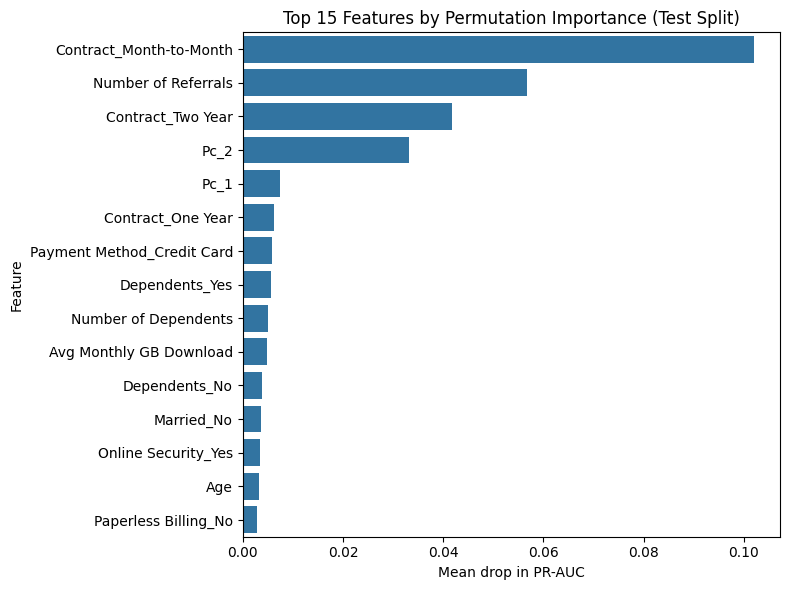

In [47]:
# ===== Permutation importance on the test split =====
importance = permutation_importance(
    selected_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
df_importance = (
    pd.DataFrame(
        {
            "Feature": X_test.columns,
            "Mean drop in PR-AUC": importance.importances_mean,
            "Std": importance.importances_std,
        }
    )
    .sort_values("Mean drop in PR-AUC", ascending=False)
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=df_importance.head(15), x="Mean drop in PR-AUC", y="Feature", ax=ax)
ax.set_title("Top 15 Features by Permutation Importance (Test Split)")
plt.tight_layout()
plt.show()

### 7.8 Assessment against Business and Data-Mining Success Criteria

The table combines the checks computed in Section 7.4 with the criteria that are met by the analysis itself. B3 also requires a pilot with a randomly held-out control group, which no offline evaluation can replace.

In [48]:
# ===== Assessment table for all success criteria (Section 2.4) =====
def status(met: bool) -> str:
    """Translate a boolean check into a status label."""
    return "Achieved" if met else "Not achieved"


d3_met = bool(criteria_checks.loc[criteria_checks["ID"] == "D3", "Met"].all())
d4_met = bool(criteria_checks.loc[criteria_checks["ID"] == "D4", "Met"].all())
b3_part1_met = bool(
    criteria_checks.loc[criteria_checks["ID"] == "B3 (part 1)", "Met"].all()
)

assessment = pd.DataFrame(
    [
        (
            "B1",
            "Consolidated view of churn",
            "Overall and segment churn rates (4.4.2, 4.4.3)",
            "Achieved",
        ),
        (
            "B2",
            "Targeted retention",
            "Driver ranking (4.4.6, 5.3.1), permutation importance "
            "(7.7) and recommendations with owners (9.5)",
            "Achieved",
        ),
        (
            "B3",
            "Proactive retention",
            f"Net value at the recall threshold "
            f"{model_row['Net value']:,.0f} (7.4); pilot not yet run",
            "Partially achieved (pilot pending)" if b3_part1_met else "Not achieved",
        ),
        (
            "D1",
            "Churn baseline",
            "Churn rate and per-category churn rates (4.4)",
            "Achieved",
        ),
        (
            "D2",
            "Association ranking",
            "Chi-square screening (5.3.1) and permutation importance (7.7)",
            "Achieved",
        ),
        (
            "D3",
            f"Recall >= {TARGET_RECALL}",
            f"Test recall {model_row['Recall']:.3f} (7.4)",
            status(d3_met),
        ),
        (
            "D4",
            "Beat the month-to-month rule",
            f"Precision {model_row['Precision']:.3f} vs "
            f"{rule_row['Precision']:.3f}; F1 {model_row['F1']:.3f} vs "
            f"{rule_row['F1']:.3f} (7.4)",
            status(d4_met),
        ),
        (
            "D5",
            "Validity",
            "Leakage safeguards (Section 5); test split used once (Section 7)",
            "Achieved",
        ),
    ],
    columns=["ID", "Criterion (Section 2.4)", "Evidence", "Status"],
)
display(assessment)

,ID,Criterion (Section 2.4),Evidence,Status
0,B1,Consolidated view of churn,"Overall and segment churn rates (4.4.2, 4.4.3)",Achieved
1,B2,Targeted retention,"Driver ranking (4.4.6, 5.3.1), permutation imp...",Achieved
2,B3,Proactive retention,"Net value at the recall threshold 342,430 (7.4...",Partially achieved (pilot pending)
3,D1,Churn baseline,Churn rate and per-category churn rates (4.4),Achieved
4,D2,Association ranking,Chi-square screening (5.3.1) and permutation i...,Achieved
5,D3,Recall >= 0.85,Test recall 0.885 (7.4),Achieved
6,D4,Beat the month-to-month rule,Precision 0.605 vs 0.470; F1 0.719 vs 0.622 (7.4),Achieved
7,D5,Validity,Leakage safeguards (Section 5); test split use...,Achieved


### 7.9 Review of the Process

**What worked**

* Leakage safeguards: outcome-describing columns are removed explicitly, every fitted preparation step uses the training split only, and the test split is used once.
* Success criteria, including a business-rule benchmark, were fixed before modelling.
* Thresholds are chosen on out-of-fold predictions and saved with the model's preprocessing artifacts, so the app repeats the exact decision rule.
* The Optuna study is stored in flat files and resumes after an interruption.

**What should be revisited in the next iteration**

* **Cross-validation optimism.** Preprocessing is fitted on the whole training split before cross-validation (Section 6). Wrapping preprocessing and model in one scikit-learn `Pipeline` would remove this optimism.
* **Undersampling.** Compare it with class weights, which keep all training data.
* **Satisfaction score.** Confirm when it is collected; if before churn, test it as a feature (Section 5.1).
* **Campaign economics.** Replace the illustrative costs with real offer and contact costs.
* **Probability calibration.** The break-even threshold flagged every customer (Section 6.6), which points to compressed probabilities. Inspect the distribution of the corrected probabilities and calibrate them on out-of-fold predictions (e.g. isotonic or sigmoid calibration) before using the break-even rule.
* **Long-contract churners.** Most churners on one- and two-year contracts are missed (Section 7.6). Features that signal dissatisfaction before contract end would help.

### 7.10 Decision on Next Steps

| Outcome | Decision |
|---|---|
| D3 and D4 are met, and campaign net value is positive | Approve the model for the tracked MLflow run and a pilot with a randomly held-out control group to measure B3 |
| D3 is met, but D4 is missed (no better than the month-to-month rule) | Do not adopt the model; use the rule, and return to Data Preparation and Modeling |
| D3 is missed | Revisit the threshold, class balancing and features, and retrain |

The cell below applies these rules to the results in Section 7.8.

In [49]:
# ===== Decision rule (table above) =====
if d3_met and d4_met and b3_part1_met:
    decision = "Approve for the tracked MLflow run and a controlled pilot (B3)."
elif d3_met and not d4_met:
    decision = (
        "Do not adopt; use the month-to-month rule "
        "and revisit preparation and modelling."
    )
elif d3_met:
    decision = (
        "Revisit the decision threshold: recall is met, but net value is not positive."
    )
else:
    decision = "Revisit the threshold, class balancing and features, then retrain."

print(f"Decision: {decision}")

Decision: Approve for the tracked MLflow run and a controlled pilot (B3).


## 8. Deployment

### 8.1 Exported Artifacts

This notebook exports everything the downstream scripts and the app need:

* `train_pca.csv`: balanced training split (equal numbers of churned and retained customers).
* `test_pca.csv`: untouched test split with the real churn ratio, for evaluation and sample payloads.
* Preprocessing artifacts: `outlier_bounds.joblib`, `log_transform_cols.joblib`, `predictor_encoder.joblib` (column schema), `target_encoder.joblib`, `<column>_scaler.joblib` and `pca.joblib`.
* Prototype artifacts: `decision_policy.json` (selected model, real churn rate, undersampling correction, both thresholds and the campaign economics; saved to `artifacts/prototype/`, where the tracked run reads it) and, in `artifacts/prototype/optuna/`, the study journal (`<study>.log`), all trials (`<study>_trials.csv`) and the best configuration (`<study>_best_params.json`).

### 8.2 From Prototype to Tracked Training (MLflow)

`pipelines/train.py` repeats Sections 6–7 as a reproducible run tracked with MLflow on DagsHub (repository `dharma.dwicahaya/telco-customer-churn-prediction`, experiment `gradient_boost_tuned`). It reads `train_pca.csv` and `test_pca.csv` from `data/processed/` and `decision_policy.json` from `artifacts/prototype/`, and writes a local copy of the final model, calibrator, decision policy and feature schema to `artifacts/model/`.

| Step | Prototype (Sections 6–7) | Tracked run (`pipelines/train.py`) |
|---|---|---|
| Baselines | Logistic regression, default Gradient Boosting | Same, each logged as a nested run with its cross-validation scores |
| Tuning | Optuna, journal file, 5 folds, F2 | Same search space and objective; the journal is stored in `optuna/` and the trials are logged as an artifact |
| Selection | Best cross-validated F2 | Same |
| Probabilities | Corrected for undersampling with a formula (6.6) | **Calibrated** with isotonic regression on out-of-fold scores, with non-churners re-weighted to the real churn rate; the calibrator is logged as `model_extras/calibrator.joblib` |
| Thresholds | Recall threshold and break-even threshold | Same rules, applied to the calibrated probabilities |
| Test evaluation | Benchmarks, criteria D3, D4 and B3 (part 1) | Same metrics, plus the Brier score and a calibration curve; criteria logged as run tags |

**Why calibration was added.** In the notebook run, the break-even threshold flagged every customer because the corrected probabilities never fell below it (Section 9.1). Isotonic calibration fitted on out-of-fold predictions maps scores to observed churn frequencies, so the break-even rule becomes meaningful. The recall threshold is unaffected, because calibration does not change how customers are ranked.

**Serving note.** Each run logs two models. `model` is the uncalibrated classifier. `churn_policy_model` is an MLflow pyfunc model that bundles the classifier, the calibrator and both thresholds, and returns the calibrated churn probability, the contact flag and a risk level (High / Medium / Low). The serving stack uses `churn_policy_model`, so the API returns exactly the decision the app shows.

### 8.3 Serving and Monitoring

* **Model server:** `mlflow models serve` (or the Docker image built by the CI workflow) serves `churn_policy_model`.
* **Inference service:** `serving/inference_client.py` sends test-split customers to the model API and, when the true label is known, sends the contact flag and the actual outcome to a feedback endpoint.
* **Monitoring:** `serving/exporter.py` exposes metrics to Prometheus, including request status, latency, payload-parsing and upstream errors, predicted risk levels and probabilities. The feedback stream allows recall and precision to be tracked on live predictions.
* **Streamlit app:** the front end for the retention team in `app/` (MurphysTelecom early-warning app), which applies the same preprocessing, calibrator and thresholds.

### 8.4 Preprocessing and Decision Order for New Customers

The app and the served model apply the saved artifacts in the same order as this notebook (`src/telco_churn/preprocessing.py` and `src/telco_churn/policy.py`): drop columns → fill missing values → cap outliers → log-transform → one-hot encode and reindex to the saved schema → scale → PCA → predict → calibrate the probability with `calibrator.joblib` from the tracked run → compare it with the threshold in that run's `decision_policy.json`.

## 9. Conclusion and Recommendations

### 9.1 Conclusion Based on Evaluation Results

**In one sentence:** one in four customers left in a single quarter, and most of them share a recognizable profile — a month-to-month contract, a short tenure, and a fiber-optic connection without protective add-ons — which makes churn predictable enough to act on early.

* **Churn baseline (Goal 1).** 26.5% of customers churned in the quarter. Churn is far above the 0.89–0.94% monthly churn reported by the largest U.S. carriers, because the data is a synthetic stress scenario (Section 1).
* **Drivers (Goal 2).** Contract type is the strongest signal (month-to-month 45.8% vs two-year 2.6%), followed by tenure, internet type, protective add-ons, payment method and offer (Section 4.4.6). These are associations; causal effects require controlled tests.
* **Early-warning model (Goal 3).** The tuned Gradient Boosting model was selected on cross-validation (F2 0.851, vs 0.843 for logistic regression and 0.837 for default Gradient Boosting) and evaluated once on the 1,409 test customers. At the recall threshold (corrected churn probability ≥ 0.268), it flags 38.8% of customers and catches 331 of the 374 churners:

| Test split | Model (recall threshold) | Month-to-month rule |
|---|---|---|
| Recall | 0.885 | 0.920 |
| Precision | 0.605 | 0.470 |
| F1 | 0.719 | 0.622 |
| Customers contacted | 38.8% | 52.0% |
| Lift | 2.28 | 1.77 |
| Campaign net value (illustrative) | 342,430 | 317,765 |

**The model reaches almost the same churners as the simple rule with a quarter fewer contacts.** Flagged customers churn 2.3 times as often as the average customer, and the expected net value of the campaign is 7.8% higher. Criteria D3 and D4 are met, and the decision in Section 7.10 is to proceed to the tracked MLflow run and a pilot with a control group. The model relies most on contract type, the number of referrals and the billing/tenure component `Pc_2` (Section 7.7), which supports keeping the referral features (Section 5.1).

Three caveats temper this result:

* **Tuning adds little.** On cross-validation, the tuned model beats logistic regression by only 0.008 F2, and both rank customers equally well (ROC-AUC 0.906). The simpler, more explainable model remains a credible alternative.
* **Churners on long contracts are mostly missed:** 14 of 24 on one-year contracts and all 6 on two-year contracts (Section 7.6). The model largely refines the month-to-month signal.
* **The break-even threshold is not usable yet.** At 0.164 it flags every customer, both out-of-fold and on the test split, so no corrected probability falls below it. This suggests the tuned model's probabilities are compressed toward the middle (hypothesis), so they need calibration before the campaign-economics rule can be applied (Section 7.9).

### 9.2 Were the Problem Statements Addressed?

1. **Problem Statement 1, a consolidated picture of churn: addressed** [B1, D1].
   The overall churn rate and the churn rate of every segment are reported (Sections 4.4.2 and 4.4.3).
2. **Problem Statement 2, quantified drivers: addressed** [B2, D2].
   Segment comparisons and the chi-square screening rank the characteristics linked to churn, and permutation importance on the test split (Section 7.7) confirms contract type, the number of referrals and the billing/tenure component `Pc_2` as the model's main inputs.
3. **Problem Statement 3, an individual early warning: addressed by the prototype, pilot pending** [B3, D3–D5].
   The prototype flags customers at risk with a saved decision rule (Section 6.6) and meets D3 and D4 on the test split (Section 7.8). Proof of real retention impact (B3) requires a pilot with a control group.

### 9.3 Were the Goals Achieved?

The goal-level summary below condenses the criterion-level assessment in Section 7.8.

| Goal | Criteria (Section 2.4) | Result | Status |
|---|---|---|---|
| 1. Churn baseline | B1, D1 | 26.5% churn; per-segment churn rates for every attribute | Achieved |
| 2. Key characteristics | B2, D2 | Contract, tenure, internet type, add-ons, payment method and offer ranked; permutation importance (7.7) | Achieved |
| 3. Early-warning model | B3, D3, D4, D5 | Test split: recall 0.885 (target ≥ 0.85); precision 0.605 and F1 0.719 vs 0.470 and 0.622 for the month-to-month rule; campaign net value 342,430 vs 317,765; pilot not yet run | D3, D4, D5 achieved; B3 partially achieved (pilot pending) |

### 9.4 Did the Solution Approach Deliver Meaningful Impact?

* **From totals to targets.** A single churn rate is broken down into segments that a non-specialist can read in minutes, which shows where retention budgets should go first.
* **Honest performance figures.** Removing outcome-describing columns and fitting every step on the training split prevents the over-optimistic results that leakage would produce.
* **Fewer wasted contacts.** Compared with contacting every month-to-month customer, the model contacts a quarter fewer customers (38.8% vs 52.0%) while flagged customers churn more often (precision 0.605 vs 0.470), which raises the expected campaign value by 7.8% under the illustrative economics.
* **A saved decision rule, not just a score.** The recall threshold and the undersampling correction are stored in `decision_policy.json`, so the Streamlit app applies exactly the rule evaluated here. The break-even rule from the campaign economics becomes usable once the probabilities are calibrated.

### 9.5 Recommendations (Prescriptive Actions)

Each recommendation names the stakeholder best placed to act (see Section 2.3). Because the evidence is associational, each action should be run as a test with a control group before a full rollout.

1. **Move month-to-month customers to longer contracts.** *Owner: marketing and offer management.*
   Month-to-month customers churn at 45.8% vs 2.6% on two-year contracts (Insight 6). Test contract-upgrade incentives on the highest-risk month-to-month customers.
2. **Strengthen the first months of the relationship.** *Owner: retention / CRM team and customer care.*
   Churners have a median tenure of about 10 months vs about 38 months for retained customers (Insight 7). An onboarding check-in during the first months can catch problems early.
3. **Review the fiber-optic experience and bundle protective add-ons.** *Owner: network and product teams.*
   Fiber-optic customers churn at 40.7%, and customers without online security or premium tech support churn at about 31% (Insight 5). Investigate service quality for fiber customers and test bundling these add-ons.
4. **Review who receives Offer E.** *Owner: marketing and offer management.*
   Customers whose last accepted offer was Offer E churn at 52.9% (Insight 6). Check whether the offer is targeted at already-risky customers or whether its terms encourage leaving.
5. **Test convenient payment options.** *Owner: finance.*
   Mailed-check and bank-withdrawal payers churn at 36.9% and 34.0% vs 14.5% for credit card (Insight 6). Test whether offering easier automatic payment changes retention.
6. **Improve the data behind the model.** *Owner: data science / MLOps, with finance.*
   Record satisfaction scores with the date they are collected, and supply real offer and contact costs, so the satisfaction feature and the campaign economics can be validated (Sections 5.1 and 2.4).

### 9.6 Limitations and Future Work

Process-related findings are listed in Section 7.9. The limitations below concern the data and the scope of the analysis.

* **Synthetic, single-quarter data.** The data is an IBM sample of a fictional company, covering one quarter as a snapshot. Patterns may not transfer to a real operator, and without per-customer dates a time-based validation is not possible.
* **New customers.** Customers who joined during the quarter are labelled as not churned, although they had little time to churn; separating them would sharpen the target definition.
* **Excluded satisfaction score.** If the score is in fact collected before churn, the current model understates the achievable performance.
* **Illustrative economics.** The campaign economics use literature-based cost ratios, not the company's actual costs, and the incremental-retention target requires a pilot with a control group.
* **Cross-validation optimism.** Preprocessing is fitted on the whole training split before cross-validation, so cross-validation scores are slightly optimistic; the test split is not affected (Section 6).
* **Undersampling and PCA.** Undersampling discards almost half of the training data, and PCA makes the billing features harder to explain to business users; both should be compared with simpler alternatives (Sections 5.3.4 and 5.3.7).